# 04 - Model 1: Engineering hypotheses and rule-based detection

*Source: the team's v1 analysis `02_performance_loss_analysis`, Phases 4 and 5 - original code and conclusions
(changed: inputs from `data/processed/`, no file saves). Then the extensions: threshold sweep, physical attribution, rejected
mild overruns, reduced speed (H9), robustness (clock shift, time grid) and the figures.*

**Question:** which actuator steps took clearly longer than the same step normally takes, is the extra time real
lost time, and which equipment does it belong to?

**Rules of this analysis (v1)**

1. No hand-picked time windows. Every limit is either measured from the data or a textbook statistical rule, and it
   is printed.
2. Every statement is one of three kinds and is labelled as such: **documented** (variable file), **measured** (this
   data), or **open question** (cannot be decided from the data).
3. Every hypothesis has its test and decision rule written down **before** the result is computed (notebook 01).

## Setup

Imports, parameters (the same values as `config.yaml`) and the hand-over of results between the notebooks (`data/processed/`, run the notebooks in order 01-06).

In [7]:
from io import StringIO
from pathlib import Path

from IPython.display import Image, display
import numpy as np
import pandas as pd
from dataclasses import dataclass, field
import re
from scipy import stats as sps
from sklearn.cluster import KMeans
from sklearn.ensemble import IsolationForest
from sklearn.metrics import adjusted_rand_score, average_precision_score, silhouette_score
from sklearn.preprocessing import StandardScaler
from itertools import combinations
import dataclasses
import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch, Patch

%matplotlib inline
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)

In [8]:
# Parameters - the same values as config.yaml
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
cfg = {'paths': {'raw_siemens': 'data/raw/Beispieldatensatz Siemens S7 SPS.csv',
           'raw_beckhoff': 'data/raw/Beispieldatensatz Beckhoff SPS.csv',
           'variable_file': 'data/raw/Variablenerklärung.xlsx',
           'reports_dir': 'reports',
           'figures_dir': 'reports/figures'},
 'timebase': {'gap_report_s': 0.5,
              'gap_cooccur_tolerance_s': 0.2,
              'resample_grids_ms': [20, 50, 76, 93, 100, 200, 500]},
 'phases': {'production_start_signal': 'E200.0',
            'curtain_signal': 'A201.0',
            'curtain_signal_beckhoff': 'VG.safeCurtainShort',
            'hmi_run_signal': 'Visual.start',
            'pallet_request_signals': ['WH.desiredPalletX', 'WH.desiredPalletY'],
            'drilling_cycle_register': 'MW22'},
 'rule': {'tukey_k': 3.0,
          'min_activations': 5,
          'min_excess_s': 'auto',
          'sweep_k': [1.5, 3.0],
          'sweep_min_excess_s': [1.0, 1.5, 1.84, 2.0, 2.5, 3.0, 4.0, 5.0],
          'sweep_merge_gap_s': [0.0, 1.0, 2.0, 5.0, 10.0],
          'merge_gap_s': 0.0},
 'ml': {'seeds': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9],
        'contamination_sweep': [0.01, 0.02, 0.05, 0.1],
        'kmeans_k': [2, 3, 4, 5, 6, 7, 8],
        'top_k': 10},
 'performance': {'bootstrap_resamples': 5000, 'bootstrap_seed': 42}}
cfg["paths"] = {k: ROOT / v for k, v in cfg["paths"].items()}
PROCESSED = ROOT / "data" / "processed"        # prepared data handed from one notebook to the next
FIGURES = cfg["paths"]["figures_dir"]          # reports/figures

In [9]:
def save_stage(name, results):
    """Write this notebook's results to data/processed/<name>.pkl for the next notebooks."""
    PROCESSED.mkdir(parents=True, exist_ok=True)
    pd.to_pickle(results, PROCESSED / f"{name}.pkl")


def load_stage(name, notebook):
    """Results of an earlier notebook; a clear message names the notebook to run first."""
    f = PROCESSED / f"{name}.pkl"
    if not f.exists():
        raise FileNotFoundError(f"data/processed/{name}.pkl is missing - run notebook {notebook} first.")
    return pd.read_pickle(f)

**Figure style** (the same cell in every notebook that saves figures): 12 x 5.4 in, 200 dpi, fonts >= 12 pt, fixed colours.

In [10]:
COLORS = {"stop": "#D64545", "overrun": "#F0A030", "normal": "#9AA5B1", "accent": "#1F7A8C",
          "navy": "#1F2A5A", "light": "#E6E9ED", "muted": "#5B6675"}


FIGSIZE = (12, 5.4)


DPI = 200


STYLE = {
    "figure.figsize": FIGSIZE, "figure.dpi": 100, "savefig.dpi": DPI, "figure.facecolor": "white",
    "axes.facecolor": "white", "savefig.facecolor": "white", "font.size": 13, "axes.titlesize": 13,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.labelsize": 13, "xtick.labelsize": 12,
    "ytick.labelsize": 12, "legend.fontsize": 12, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#5B6675", "axes.labelcolor": "#1F2A5A", "text.color": "#1F2A5A",
    "xtick.color": "#1F2A5A", "ytick.color": "#1F2A5A", "legend.frameon": False,
}


def apply_style():
    plt.rcParams.update(STYLE)


apply_style()
FIGURES.mkdir(parents=True, exist_ok=True)

**Data container and reset presses**

- `on_intervals`: (start, end) of every period in which boolean ``x`` is True.
- `PLCData`: Analysis-ready recording of one PLC.
- `hmi_reset_times`: Times of every press of the HMI reset button E200.0.

In [11]:
def on_intervals(t, x) -> list[tuple[float, float]]:
    """(start, end) of every period in which boolean ``x`` is True.

    start = time of the first True sample; end = time of the first False
    sample afterwards, or the last sample if still True at the end.
    """
    t = np.asarray(t, dtype=float)
    x = np.asarray(x, dtype=bool).astype(int)
    change = np.diff(np.concatenate(([0], x, [0])))
    starts = np.flatnonzero(change == 1)
    ends = np.minimum(np.flatnonzero(change == -1), len(t) - 1)
    return [(float(t[a]), float(t[b])) for a, b in zip(starts, ends)]


@dataclass
class PLCData:
    """Analysis-ready recording of one PLC."""

    name: str
    frame: pd.DataFrame                 # timestamp, t, one column per signal
    signals: list[str]
    raw_shape: tuple[int, int]          # rows, signal columns (as in the file)
    excluded_rows: pd.DataFrame = field(default_factory=pd.DataFrame)
    dropped_columns: list[str] = field(default_factory=list)


def hmi_reset_times(data: dict, cfg: dict) -> list[float]:
    s = data["Siemens"].frame
    return [a for a, _ in on_intervals(s["t"], s[cfg["phases"]["production_start_signal"]])]

## Recap: data and preparation (notebooks 02-03)

The data prepared by notebooks 02 and 03 (`data/processed/`); the names below are the names used by the original v1
cells.

In [12]:
s02 = load_stage("02_data", "02_data_understanding_and_cleaning")
s03 = load_stage("03_prepared", "03_data_preparation")
data = {k: PLCData(**v) if k in ("Siemens", "Beckhoff") else v for k, v in s02.pop("data").items()}
ctx = {"cfg": cfg, "data": data, **s02, **s03}
sie, bec = data["Siemens"].frame, data["Beckhoff"].frame
PLC = {"Siemens": sie, "Beckhoff": bec}
RECORDING_END = ctx["end"]
DETECTION_LIMIT_S, SYNC_TOLERANCE_S = ctx["limit"], ctx["tol"]        # notebook 02, part 4
PRODUCTION_START = ctx["p0"]                                            # notebook 02, part 6
reset_presses = hmi_reset_times(data, cfg)
cycles = ctx["cycles"]                                                  # notebook 03, part 6 (H2)
acts = ctx["acts"][ctx["acts"]["in_production"]].reset_index(drop=True)  # notebook 03, part 7
sie_doc = pd.read_excel(cfg["paths"]["variable_file"], sheet_name="Siemens")
bec_doc = pd.read_excel(cfg["paths"]["variable_file"], sheet_name="Beckhoff")
print(f"production window {PRODUCTION_START:.2f} to {RECORDING_END:.2f} s, {len(acts)} activations, "
      f"detection limit {DETECTION_LIMIT_S:.2f} s, sync tolerance {SYNC_TOLERANCE_S:.3f} s")

production window 8.93 to 505.80 s, 677 activations, detection limit 1.84 s, sync tolerance 0.169 s


### Helper functions (v1 step 2.2)

- `on_intervals`: start and end of every ON-period of a boolean signal.
  One ON-period of an actuator output is called an **activation**.
- `edge_times`: the moments a signal switches.
- `step_before`: the logging step that ends at a given sample. It is
  the timing uncertainty of an edge at that sample.
- `describe`: station and meaning of a signal from the variable file.

In [13]:
# Colours for all figures (grey = normal, orange = flagged as too long).
INK, INK_2, GRID = "#0b0b0b", "#52514e", "#e4e2dd"
C_NORMAL, C_FLAG = "#a8a69f", "#eb6834"
C_SAFETY, C_HMI = "#2a78d6", "#6250d6"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2,
    "xtick.color": INK_2, "ytick.color": INK_2, "text.color": INK,
    "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 10,
})


def on_intervals(t, x):
    """Return (start, end) of every period in which boolean x is True.

    start = time of the first sample that is True,
    end = time of the first sample that is False again
    (or the last sample, if the signal is still True at the end).
    """
    t = np.asarray(t, dtype=float)
    x = np.asarray(x, dtype=bool).astype(int)
    change = np.diff(np.concatenate(([0], x, [0])))
    starts = np.flatnonzero(change == 1)
    ends = np.minimum(np.flatnonzero(change == -1), len(t) - 1)
    return [(float(t[a]), float(t[b])) for a, b in zip(starts, ends)]


def edge_times(t, x):
    """Return the times at which boolean x changes its value."""
    x = np.asarray(x, dtype=bool).astype(int)
    return np.asarray(t, dtype=float)[1:][np.diff(x) != 0]


def step_before(df, time):
    """Logging step (s) between the sample at `time` and the one before."""
    t = df["t"].to_numpy()
    i = int(np.clip(np.searchsorted(t, time), 1, len(t) - 1))
    return t[i] - t[i - 1]


def overlap(a_start, a_end, b_start, b_end):
    """True if the windows [a_start, a_end] and [b_start, b_end] share
    at least one moment."""
    return a_start <= b_end and b_start <= a_end


BEC_STATION = bec_doc.set_index("Variablenname / Beschreibung")["Station"]
SIE_DOC = sie_doc.set_index("Variablenname")
# Readable names for Beckhoff outputs. The variable file only gives the
# station, so these labels are a reading of the signal names.
BEC_LABEL = {
    "WH.Q1_beltForward": "conveyor belt forward",
    "WH.Q2_beltBackward": "conveyor belt backward",
    "WH.Q3_horRack": "horizontal axis towards rack",
    "WH.Q4_horBelt": "horizontal axis towards belt",
    "WH.Q7_cantForw": "cantilever forward",
    "WH.Q8_cantBack": "cantilever backward",
    "VG.Q7_compressorON": "compressor (one pick-and-place)",
}


def describe(signal):
    """Station and meaning of a signal, taken from the variable file."""
    if signal in SIE_DOC.index:
        row = SIE_DOC.loc[signal]
        text = row["Kommentar"].replace("(output)", "").strip()
        return f"{row['Station']}: {text} ({signal})"
    label = BEC_LABEL.get(signal, signal)
    return f"{BEC_STATION.get(signal, 'Beckhoff')}: {label} ({signal})"


print("helper functions ready")

helper functions ready


## Phase 4 – Modelling: detecting activations that are too long

### Step 4.1 – H3: the detection rule

For each output, the normal duration is described by robust statistics
that one long value cannot distort: the **median** and the
**interquartile range** IQR = Q3 - Q1. An activation is flagged if

1. its duration is above **Tukey's fence** Q3 + k x IQR, with the
   textbook value k = 3 ("far out" values), and
2. it is longer than the median by at least the **detection limit**
   (1.84 s, measured in Step 2.3).

Outputs with fewer than 5 activations are skipped, because quartiles of
fewer values are not meaningful (their effect is checked below).

Flagged activations that **overlap in time** form one **event**. No
time gap parameter is needed for this.

In [14]:
TUKEY_K = 3.0          # Tukey's "far out" fence: Q3 + 3 * IQR
MIN_ACTIVATIONS = 5    # quartiles need at least 5 values to be meaningful


def normal_durations(acts):
    """Median, quartiles and maximum of the ON-duration per output."""
    grouped = acts.groupby("signal")["duration"]
    stats = pd.DataFrame({
        "n": grouped.size(),
        "median": grouped.median(),
        "q1": grouped.quantile(0.25),
        "q3": grouped.quantile(0.75),
        "max": grouped.max(),
    })
    stats["iqr"] = stats["q3"] - stats["q1"]
    return stats


def flag_long(acts, stats, k=TUKEY_K, limit=DETECTION_LIMIT_S):
    """Activations above the Tukey fence and longer than normal by at
    least `limit` seconds."""
    data = acts.join(stats[["n", "median", "q3", "iqr"]], on="signal")
    data["fence"] = data["q3"] + k * data["iqr"]
    data["excess"] = data["duration"] - data["median"]
    is_long = ((data["n"] >= MIN_ACTIVATIONS)
               & (data["duration"] > data["fence"])
               & (data["excess"] >= limit))
    return data[is_long].sort_values("start").reset_index(drop=True)


def group_overlapping(flags):
    """Give overlapping flagged activations the same event number."""
    numbers, number, group_end = [], 0, -np.inf
    for start, end in zip(flags["start"], flags["end"]):
        if start > group_end:  # no overlap with the current event
            number += 1
            group_end = end
        group_end = max(group_end, end)
        numbers.append(number)
    return numbers


stats = normal_durations(acts)
flags = flag_long(acts, stats)
flags["event"] = [f"E{n}" for n in group_overlapping(flags)]
flag_keys = set(zip(flags["signal"], flags["start"]))
print(flags[["event", "plc", "signal", "start", "end", "duration",
             "median", "fence", "excess"]].round(2).to_string(index=False))
print(f"\n{len(flags)} long activations -> {flags['event'].nunique()} events")

event      plc             signal  start    end  duration  median  fence  excess
   E1 Beckhoff      WH.Q3_horRack 252.42 266.03     13.61    3.10   9.64   10.50
   E1  Siemens               A1.7 254.15 272.17     18.03    9.22   9.44    8.80
   E2 Beckhoff  WH.Q1_beltForward 291.28 299.08      7.80    0.86   1.29    6.94
   E3 Beckhoff WH.Q2_beltBackward 314.84 321.63      6.79    0.57   0.74    6.22
   E4 Beckhoff  WH.Q1_beltForward 350.80 360.42      9.62    0.86   1.29    8.77
   E5  Siemens               A0.7 363.10 371.09      7.99    5.77   6.75    2.21
   E6  Siemens               A1.0 385.07 390.14      5.07    0.99   1.22    4.08
   E6 Beckhoff     WH.Q7_cantForw 387.44 400.86     13.43    3.06   3.30   10.37
   E7 Beckhoff      WH.Q3_horRack 452.99 463.28     10.29    3.10   9.64    7.19
   E8 Beckhoff     WH.Q8_cantBack 468.45 476.48      8.03    3.11   3.21    4.92

10 long activations -> 8 events


### Step 4.2 – How sensitive is the result to the two settings?

The rule has two settings: the fence factor k and the minimum excess.
Both are varied. The outputs skipped for having fewer than 5
activations are listed with their largest excess.

In [15]:
sensitivity = []
for k in (1.5, 3.0):
    for limit in (1.0, DETECTION_LIMIT_S, 3.0):
        found = flag_long(acts, stats, k=k, limit=limit)
        sensitivity.append({
            "tukey_k": k,
            "min_excess_s": round(limit, 2),
            "long_activations": len(found),
            "events": len(set(group_overlapping(found))),
        })
sensitivity = pd.DataFrame(sensitivity)
print(sensitivity.to_string(index=False))

few = stats[stats["n"] < MIN_ACTIVATIONS].copy()
few["max_excess"] = few["max"] - few["median"]
print(f"\nOutputs skipped (fewer than {MIN_ACTIVATIONS} activations):")
print(few[["n", "median", "max", "max_excess"]].round(2).to_string())

wide = stats[stats["iqr"] > DETECTION_LIMIT_S]
print("\nOutputs whose normal duration itself varies by more than the "
      "detection limit (IQR):")
print(wide[["n", "median", "q1", "q3", "max"]].round(2).to_string())

n_events = flags["event"].nunique()
at_limit = sensitivity[sensitivity["min_excess_s"]
                       == round(DETECTION_LIMIT_S, 2)]
stable = at_limit["events"].nunique() == 1
H3_ACCEPTED = bool((1 <= n_events <= 10) and stable)
print(f"\n{n_events} events, same count for k = 1.5 and k = 3: {stable} "
      f"-> H3 accepted: {H3_ACCEPTED}")

 tukey_k  min_excess_s  long_activations  events
     1.5          1.00                29      16
     1.5          1.84                10       8
     1.5          3.00                 9       7
     3.0          1.00                14      10
     3.0          1.84                10       8
     3.0          3.00                 9       7

Outputs skipped (fewer than 5 activations):
        n  median   max  max_excess
signal                             
A0.2    4    0.53  0.54        0.01
A0.3    3    0.46  0.50        0.04
A0.4    3    0.54  1.87        1.32

Outputs whose normal duration itself varies by more than the detection limit (IQR):
                     n  median     q1     q3    max
signal                                             
A1.6                10   29.68  22.43  44.27  54.64
A4.1                 9   52.02  39.46  64.54  74.29
VG.Q7_compressorON  16    7.77   6.65   9.23   9.79

8 events, same count for k = 1.5 and k = 3: True -> H3 accepted: True


**Result H3 (measured):**

- 677 activations of 41 outputs were tested. **10 activations** are
  too long. They form **8 events** (E1 to E8), inside the 1 to 10
  given in the task.
- At the detection limit the result is the same for k = 1.5 and k = 3.
  Below the detection limit (1 s) many more small deviations appear,
  which cannot be separated from logging gaps. Above it (3 s) only the
  weakest event E5 (+2.2 s) disappears.
- The skipped outputs (sorting pushers) never exceed their median by
  more than 1.32 s, so skipping them changes nothing.
- Limit of the rule: for the compressor `A1.6` and the oven door
  `A4.1` the normal duration varies by tens of seconds (they hold a
  state while other steps run), so the rule cannot judge them. The
  robot compressor has two normal lengths (short and long move); its
  wide fence is correct and none of its activations is flagged.
- **H3 is accepted.**

## Phase 5 – Evaluation of the detections

### Step 5.1 – H4: are the detections real?

Two alternative explanations are tested for each flagged activation.

- **Logging artefact.** Each edge can be off by the logging step before
  it. Both uncertainties are subtracted from the excess. If something
  is left, the activation was too long even in the worst case.
- **Longer travel (rack position).** The activation is compared with
  the **longest normal** activation of the same output. That one
  already includes the farthest rack position in the recording.

In [16]:
flags["edge_uncertainty_s"] = [
    step_before(PLC[p], s) + step_before(PLC[p], e)
    for p, s, e in zip(flags["plc"], flags["start"], flags["end"])
]
flags["worst_case_excess_s"] = flags["excess"] - flags["edge_uncertainty_s"]

is_flagged = np.array([k in flag_keys
                       for k in zip(acts["signal"], acts["start"])])
longest_normal = acts[~is_flagged].groupby("signal")["duration"].max()
flags["longest_normal_s"] = flags["signal"].map(longest_normal)
flags["above_longest_normal_s"] = (flags["duration"]
                                   - flags["longest_normal_s"])

print(flags[["event", "signal", "duration", "edge_uncertainty_s",
             "worst_case_excess_s", "longest_normal_s",
             "above_longest_normal_s"]].round(2).to_string(index=False))
H4_ACCEPTED = bool(
    (flags["worst_case_excess_s"] > 0).all()
    and (flags["above_longest_normal_s"] >= DETECTION_LIMIT_S).all()
)
print(f"\nH4 accepted (all detections are real, not gaps or distance): "
      f"{H4_ACCEPTED}")

event             signal  duration  edge_uncertainty_s  worst_case_excess_s  longest_normal_s  above_longest_normal_s
   E1      WH.Q3_horRack     13.61                0.17                10.33              4.38                    9.23
   E1               A1.7     18.03                0.15                 8.65              9.26                    8.76
   E2  WH.Q1_beltForward      7.80                0.19                 6.75              0.96                    6.84
   E3 WH.Q2_beltBackward      6.79                0.19                 6.04              0.65                    6.14
   E4  WH.Q1_beltForward      9.62                0.21                 8.56              0.96                    8.66
   E5               A0.7      7.99                0.15                 2.06              6.03                    1.96
   E6               A1.0      5.07                0.15                 3.93              1.05                    4.02
   E6     WH.Q7_cantForw     13.43                0.18  

**Result H4 (measured):** the edge uncertainty is at most 0.21 s, so
every detection stays clearly too long (worst case still +2.1 s to
+10.3 s). Every detection is also longer than the longest normal
activation of the same output by at least the detection limit, so a
far rack position cannot explain it. The weakest case is again E5
(+1.96 s above the longest normal run). **H4 is accepted.**

### Step 5.2 – H5: standstill or slow motion? (a) paired outputs

The Beckhoff file contains two signals for every warehouse motor
direction, for example `WH.Q3_horRack` and
`WH.Q3_horizontal_towards_rack`. The variable file does not explain the
difference. We **measure** how they behave: windows in which the first
is ON and its partner is OFF.

In [17]:
PAIRS = {
    "WH.Q3_horRack": "WH.Q3_horizontal_towards_rack",
    "WH.Q4_horBelt": "WH.Q4_horizontal_towards_conveyor_belt",
    "WH.Q5_verDown": "WH.Q5_vertical_downward",
    "WH.Q6_verUP": "WH.Q6_vertical_upward",
    "WH.Q7_cantForw": "WH.Q7_cantilever_forward",
    "WH.Q8_cantBack": "WH.Q8_cantilever_backward",
}
rows = []
for first, second in PAIRS.items():
    only_first = bec[first] & ~bec[second]
    for start, end in on_intervals(bec["t"], only_first):
        if start >= PRODUCTION_START:
            rows.append((first, second, start, end, end - start))
mismatch = pd.DataFrame(
    rows, columns=["first", "second", "start", "end", "duration"])
drive_off = mismatch[mismatch["duration"] >= DETECTION_LIMIT_S]
shorter = mismatch.loc[mismatch["duration"] < DETECTION_LIMIT_S, "duration"]

print(f"Windows with the first signal ON and its partner OFF: "
      f"{len(mismatch)}")
print(f"  shorter than the detection limit: {len(shorter)} "
      f"(longest {shorter.max():.2f} s)")
print(f"  longer than the detection limit:  {len(drive_off)}")
print(drive_off.round(2).to_string(index=False))

Windows with the first signal ON and its partner OFF: 111
  shorter than the detection limit: 107 (longest 0.26 s)
  longer than the detection limit:  4
         first                        second  start    end  duration
 WH.Q3_horRack WH.Q3_horizontal_towards_rack 252.42 264.26     11.84
 WH.Q3_horRack WH.Q3_horizontal_towards_rack 453.09 460.68      7.58
WH.Q7_cantForw      WH.Q7_cantilever_forward 390.10 400.40     10.30
WH.Q8_cantBack     WH.Q8_cantilever_backward 468.45 473.34      4.89


**Measured:** in normal operation the two signals of a pair switch
within 0.26 s of each other (107 short windows). Only 4 windows are
long (4.9 to 11.8 s). In these the first signal stays ON while its
partner is OFF. They lie inside events E1, E6, E7 and E8.

The encoder test in the next step shows that the axis does not move
while the partner signal is OFF. So the partner behaves like the
**motor output** and the first signal like the **request** (a reading
that is consistent with the data, not documented).

### Step 5.3 – H5 (b) encoder pulses of the horizontal axis

The horizontal warehouse axis has two encoder channels
(`WH.B1/B2_encoder_horizontal_impuls`). A moving axis produces encoder
edges. For every horizontal move, the longest time without any encoder
edge is measured.

Note: the logger samples only about 11 times per second, which is close
to the pulse rate. Pulse **counts** are therefore not a reliable speed
measure. Only "pulses present / no pulse for seconds" is used.

In [18]:
ENCODERS = ["WH.B1_encoder_horizontal_impuls1",
            "WH.B2_encoder_horizontal_impuls2"]
pulse_times = np.sort(np.concatenate(
    [edge_times(bec["t"], bec[c]) for c in ENCODERS]))


def longest_silence(start, end):
    """Longest time inside [start, end] without any encoder edge."""
    inside = pulse_times[(pulse_times > start) & (pulse_times < end)]
    return float(np.diff(np.concatenate(([start], inside, [end]))).max())


moves = acts[acts["signal"].isin(["WH.Q3_horRack", "WH.Q4_horBelt"])].copy()
moves["longest_silence_s"] = [longest_silence(s, e)
                              for s, e in zip(moves["start"], moves["end"])]
moves["flagged"] = [k in flag_keys
                    for k in zip(moves["signal"], moves["start"])]
print(moves[["signal", "start", "duration", "longest_silence_s",
             "flagged"]].round(2).to_string(index=False))
normal_silence = moves.loc[~moves["flagged"], "longest_silence_s"].max()
print(f"\nLongest encoder silence in a normal move: {normal_silence:.2f} s")

       signal  start  duration  longest_silence_s  flagged
WH.Q4_horBelt  12.02      3.07               0.38    False
WH.Q3_horRack  34.39      3.06               0.37    False
WH.Q4_horBelt  45.43      1.41               0.28    False
WH.Q4_horBelt  54.76      1.74               0.26    False
WH.Q3_horRack  88.66      1.74               0.56    False
WH.Q3_horRack  98.50      2.57               0.19    False
WH.Q4_horBelt 109.01      4.47               0.56    False
WH.Q3_horRack 144.71      4.38               0.28    False
WH.Q4_horBelt 156.14      1.38               0.28    False
WH.Q4_horBelt 164.59      3.14               0.47    False
WH.Q3_horRack 199.87      3.15               0.30    False
WH.Q4_horBelt 210.07      1.38               0.28    False
WH.Q4_horBelt 218.62      1.61               0.38    False
WH.Q3_horRack 252.42     13.61              11.84     True
WH.Q3_horRack 273.14      2.63               0.37    False
WH.Q4_horBelt 283.44      4.36               0.33    Fal

**Measured:** in the 24 normal horizontal moves the encoder is never
silent for more than 0.88 s. In the two flagged moves it is silent for
**11.84 s (E1)** and **7.58 s (E7)**, exactly as long as the motor
output of the pair was OFF. The axis **stood still**, it did not move
slowly.

### Step 5.4 – H5 (c) belt and small conveyor: when does the part
arrive?

The warehouse belt and the small conveyor of the drilling station have
**no** encoder. What can be measured is when the transported part
reaches the light barrier at the destination:

- Warehouse belt: the last change of the light barriers
  `WH.I2` (inside) / `WH.I3` (outside) during the belt run.
- Small conveyor: the first change of `E1.0` ("lightbarrier in small
  belt", documented) during the conveyor run.

We also check whether the outside barrier changes while the belt is
**not** running.

In [19]:
barrier_edges = np.sort(np.concatenate([
    edge_times(bec["t"], bec[c])
    for c in ("WH.I2_Light_barrier_inside", "WH.I3_Light_barrier_outside")
]))
belt = acts[acts["signal"].isin(
    ["WH.Q1_beltForward", "WH.Q2_beltBackward"])].copy()
last_barrier = np.array([
    barrier_edges[(barrier_edges >= s) & (barrier_edges <= e)].max()
    for s, e in zip(belt["start"], belt["end"])
])
belt["barrier_reached_after_s"] = last_barrier - belt["start"]
belt["belt_off_after_barrier_s"] = belt["end"] - last_barrier
belt["flagged"] = [k in flag_keys for k in zip(belt["signal"], belt["start"])]
print(belt[["signal", "start", "duration", "barrier_reached_after_s",
            "belt_off_after_barrier_s", "flagged"]]
      .round(2).to_string(index=False))

belt_on = bec["WH.Q1_beltForward"] | bec["WH.Q2_beltBackward"]
belt_off_both = ~belt_on & ~belt_on.shift(fill_value=True)
for barrier in ("WH.I2_Light_barrier_inside", "WH.I3_Light_barrier_outside"):
    changed = bec[barrier].astype(int).diff().fillna(0).ne(0)
    times = bec.loc[changed & belt_off_both
                    & (bec["t"] >= PRODUCTION_START), "t"]
    print(f"\n{barrier} changes while both belt outputs are OFF "
          f"({len(times)}x):", times.round(2).tolist())

            signal  start  duration  barrier_reached_after_s  belt_off_after_barrier_s  flagged
 WH.Q1_beltForward  18.57      0.91                     0.46                      0.45    False
WH.Q2_beltBackward  30.14      0.55                     0.55                      0.00    False
 WH.Q1_beltForward  60.05      0.85                     0.54                      0.31    False
WH.Q2_beltBackward  84.54      0.48                     0.48                      0.00    False
 WH.Q1_beltForward 117.02      0.85                     0.43                      0.42    False
WH.Q2_beltBackward 140.47      0.58                     0.58                      0.00    False
 WH.Q1_beltForward 171.24      0.80                     0.43                      0.37    False
WH.Q2_beltBackward 195.68      0.60                     0.50                      0.10    False
 WH.Q1_beltForward 223.73      0.86                     0.48                      0.38    False
WH.Q2_beltBackward 248.17      0.65     

In [20]:
part_edges = edge_times(sie["t"], sie["E1.0"])
conveyor = acts[acts["signal"] == "A0.7"].copy()
first_edge = []
for s, e in zip(conveyor["start"], conveyor["end"]):
    inside = part_edges[(part_edges >= s) & (part_edges <= e)]
    first_edge.append(inside.min() - s if len(inside) else np.nan)
conveyor["part_at_barrier_after_s"] = first_edge
conveyor["flagged"] = [k in flag_keys
                       for k in zip(conveyor["signal"], conveyor["start"])]
print(conveyor[["signal", "start", "duration", "part_at_barrier_after_s",
                "flagged"]].round(2).to_string(index=False))

print("\nDrill time variables: every change of value in the recording")
for variable in ("MD28", "MW32"):
    changed = sie[variable].diff().fillna(0).ne(0)
    print(f"  {variable}: changes at t =",
          sie.loc[changed, "t"].round(2).tolist())
drill = acts[acts["signal"] == "A1.0"]
print("Drill (A1.0) ON-durations:", drill["duration"].round(2).tolist())

signal  start  duration  part_at_barrier_after_s  flagged
  A0.7  50.46      5.77                     0.99    False
  A0.7 122.38      5.60                     0.84    False
  A0.7 147.54      5.70                     1.00    False
  A0.7 201.60      5.38                     0.84    False
  A0.7 277.00      5.80                      NaN    False
  A0.7 321.70      5.88                     1.00    False
  A0.7 363.10      7.99                     2.56     True
  A0.7 401.42      6.03                     0.77    False
  A0.7 449.41      3.73                      NaN    False

Drill time variables: every change of value in the recording
  MD28: changes at t = [385.07, 390.06]
  MW32: changes at t = [385.07, 390.06]
Drill (A1.0) ON-durations: [0.99, 1.05, 1.03, 0.94, 0.98, 1.0, 0.94, 5.07, 0.97]


**Measured:**

- **Belt rule:** in all 18 belt runs the belt switches off 0 to 0.45 s
  after the last barrier change. The belt runs **until the pallet
  reaches the barrier**.
- Normally the pallet reaches the barrier after 0.4 to 0.65 s. In E2,
  E3 and E4 it takes **7.5 s, 6.7 s and 9.3 s**. The belt was ON the
  whole time. Without a belt encoder we cannot tell whether the pallet
  stood still (blocked) or moved slowly. Both are performance losses.
- The inside barrier `WH.I2` normally changes twice per cycle while the
  belt is off (the cantilever takes or puts the pallet). The outside
  barrier `WH.I3` changes with the belt off **only 4 times, all in the
  cycles of E2/E3 and E4** (308.3 / 310.8 s and 361.3 / 364.1 s).
  Something moved in front of the outside barrier while no belt was
  running. What it was is an **open question**.
- **E5, small conveyor:** the part reached the barrier `E1.0` after
  2.56 s instead of 0.77 to 1.00 s. In two runs no barrier edge was
  logged at all (277.0 s and 449.4 s, the second was cut by a safety
  stop).
- **E6, drill:** the drill is normally ON for 0.94 to 1.05 s. In E6 it
  is ON for 5.07 s. The drill-time variables `MD28` and `MW32`
  (documented: "Drilling time in second") change value **only** during
  this one drill run, 385.07 to 390.06 s.

### Step 5.5 – H6: what caused the events?

Candidate causes that stop the machine on purpose and are visible in
the data:

- **Safety curtain stop:** `A201.0` ("Safetydata from curtain to
  beckhoff", documented) goes low. Checked: the safety lamp bit `M0.3`
  ("1 segment red ON", documented) is ON in the same window, and the
  window ends with a press of the reset button `E200.0` (documented).
- **HMI stop:** `Visual.start` (station "Visualization") goes low and
  `Visual.Stoplight` goes high. Not documented beyond the station,
  reading of the names.

In [21]:
lamp = on_intervals(sie["t"], sie["M0.3"])
stop_light = on_intervals(bec["t"], bec["Visual.Stoplight"])
causes = []
for start, end in on_intervals(sie["t"], ~sie["A201.0"].astype(bool)):
    if start < PRODUCTION_START:
        continue
    reset = min(reset_presses, key=lambda r: abs(r - end))
    causes.append({
        "cause": "Safety curtain stop (A201.0 low)",
        "start": start, "end": end, "duration": end - start,
        "light_same_window": any(
            abs(a - start) <= SYNC_TOLERANCE_S
            and abs(b - end) <= SYNC_TOLERANCE_S for a, b in lamp),
        "ended_by_reset": abs(reset - end) <= SYNC_TOLERANCE_S,
    })
for start, end in on_intervals(bec["t"], ~bec["Visual.start"].astype(bool)):
    causes.append({
        "cause": "HMI stop (Visual.start low)",
        "start": start, "end": end, "duration": end - start,
        "light_same_window": any(
            abs(a - start) <= SYNC_TOLERANCE_S
            and abs(b - end) <= SYNC_TOLERANCE_S for a, b in stop_light),
        "ended_by_reset": False,
    })
causes = pd.DataFrame(causes)
print("light_same_window = M0.3 for the curtain, Visual.Stoplight for HMI")
print(causes.round(2).to_string(index=False))

light_same_window = M0.3 for the curtain, Visual.Stoplight for HMI
                           cause  start    end  duration  light_same_window  ended_by_reset
Safety curtain stop (A201.0 low) 255.40 264.29      8.90               True            True
Safety curtain stop (A201.0 low) 390.06 400.44     10.38               True            True
Safety curtain stop (A201.0 low) 453.14 460.74      7.60               True            True
     HMI stop (Visual.start low) 468.55 473.45      4.90               True           False


### Step 5.6 – The event table

For each event:

- **lost_time_s:** how much longer than normal the most delayed output
  was ON (duration minus median). One rule for every event.
- **standstill_proven:** a long paired-output window or encoder silence
  (Steps 5.2 and 5.3) lies inside the event.
- **cause:** a cause window from Step 5.5 that overlaps the event.
- **abnormal_before_cause_s:** how long something was already abnormal
  before the cause window started. The first abnormal moment is the
  earliest of: the start of a long paired-output window, or the moment
  an output passes its normal (median) duration. Values within the sync
  tolerance count as 0.
- **oee_category:** standstill proven -> idle time / short stop.
  Otherwise the two performance sub-types cannot be separated.

In [22]:
cycle_of = {}
for _, c in cycles.iterrows():
    for name, grp in flags.groupby("event"):
        if c["start_s"] <= grp["start"].min() < c["end_s"]:
            cycle_of[name] = int(c["cycle"])

event_rows = []
for name, grp in flags.groupby("event", sort=False):
    start, end = grp["start"].min(), grp["end"].max()
    hits = causes[[overlap(start, end, a, b)
                   for a, b in zip(causes["start"], causes["end"])]]
    off = drive_off[[overlap(start, end, a, b)
                     for a, b in zip(drive_off["start"], drive_off["end"])]]
    silent = moves[moves["flagged"] & moves["start"].between(start, end)]
    standstill = bool(len(off) > 0 or (
        silent["longest_silence_s"] >= DETECTION_LIMIT_S).any())
    first_abnormal = min(list(grp["start"] + grp["median"])
                         + list(off["start"]))
    if len(hits):
        cause = hits.iloc[0]
        lead = cause["start"] - first_abnormal
        lead = lead if lead > SYNC_TOLERANCE_S else 0.0
        cause_text = (f"{cause['cause']} {cause['start']:.1f} to "
                      f"{cause['end']:.1f} s")
    else:
        lead, cause_text = np.nan, "no cause signal in the data"
    event_rows.append({
        "event": name,
        "cycle": cycle_of.get(name),
        "start_s": start,
        "end_s": end,
        "lost_time_s": grp["excess"].max(),
        "equipment": "; ".join(describe(s) for s in grp["signal"]),
        "standstill_proven": standstill,
        "cause": cause_text,
        "abnormal_before_cause_s": lead,
        "oee_category": ("Idle time / short stop" if standstill else
                         "Short stop or reduced speed (not separable)"),
    })
events = pd.DataFrame(event_rows)
print(events.drop(columns="equipment").round(1).to_string(index=False))
print()
for _, ev in events.iterrows():
    print(f"{ev['event']}: {ev['equipment']}")

n_standstill = int(events["standstill_proven"].sum())
n_cause = int((events["cause"] != "no cause signal in the data").sum())
print(f"\nStandstill proven for {n_standstill} of {len(events)} events")
print(f"Cause found for {n_cause} of {len(events)} events")

event  cycle  start_s  end_s  lost_time_s  standstill_proven                                             cause  abnormal_before_cause_s                                oee_category
   E1      5    252.4  272.2         10.5               True Safety curtain stop (A201.0 low) 255.4 to 264.3 s                      3.0                      Idle time / short stop
   E2      6    291.3  299.1          6.9              False                       no cause signal in the data                      NaN Short stop or reduced speed (not separable)
   E3      6    314.8  321.6          6.2              False                       no cause signal in the data                      NaN Short stop or reduced speed (not separable)
   E4      7    350.8  360.4          8.8              False                       no cause signal in the data                      NaN Short stop or reduced speed (not separable)
   E5      7    363.1  371.1          2.2              False                       no cause signal i

### The Model 1 stage as one function, checked against the cells above

The functions below run the same rule and the evidence steps of this notebook as one stage (independent PLC
evidence, consolidation, confidence, attribution, reduced speed); the extensions below use its results. They must
flag the same activations as the original cells above. One refinement is deliberate: the stage leaves the run that is still ON at the end of the recording
(`WH.Q7_cantForw`, 503.8 s - its true length is unknown) out of the normal duration. That moves the median of
`WH.Q7_cantForw` by 0.002 s, so the excess of E6 differs by 0.002 s; nothing else changes.

**Model 1 functions**

- `edge_times`: Times at which ``x`` changes value (time of the first new sample).
- `step_before`: Logging step that ends at the sample logged at ``time``.
- `overlaps`: True if two time windows share at least one moment.
- `STOP_TOL_S`: Tolerance (s) for 'cut by' / 'restarted after' a stop window.
- `cut_by_stop`: The run ended at (or contains) the start of a stop window.
- `resumed_after_stop`: True if an activation starts right after a stop window ends.

In [23]:
def edge_times(t, x) -> np.ndarray:
    """Times at which ``x`` changes value (time of the first new sample)."""
    x = np.asarray(x)
    return np.asarray(t, dtype=float)[1:][x[1:] != x[:-1]]


def step_before(t: np.ndarray, time: float) -> float:
    """Logging step that ends at the sample logged at ``time``.

    An edge logged at ``time`` happened somewhere in (time - step, time], so
    this is the timing uncertainty of that edge.
    """
    t = np.asarray(t, dtype=float)
    i = int(np.clip(np.searchsorted(t, time), 1, len(t) - 1))
    return float(t[i] - t[i - 1])


def overlaps(a0, a1, b0, b1) -> bool:
    return a0 <= b1 and b0 <= a1


# One logging step of either PLC: edges of the same stop can be logged this
# far apart on the two PLCs (measured offset <= 0.09 s, median steps 0.08/0.09 s).
STOP_TOL_S = 0.25


def cut_by_stop(s: float, e: float, stops: pd.DataFrame) -> bool:
    """The run ended at (or contains) the start of a stop window."""
    return bool(((stops["start_s"] > s) & (stops["start_s"] <= e + STOP_TOL_S)
                 & (stops["start_s"] >= e - STOP_TOL_S)).any())


def resumed_after_stop(s: float, stops: pd.DataFrame) -> bool:
    return bool((np.abs(stops["end_s"] - s) <= STOP_TOL_S).any())

- `scored_activations`: Activations usable for duration statistics: in production, complete.
- `normal_durations`: Median, quartiles, IQR and extremes of the ON duration per output.
- `flag_long`: Activations above the Tukey fence and longer than the median by at least the minimum excess.
- `group_events`: Event number per flagged activation: overlapping (or closer than
- `detect`: The Model 1 rule: normal durations, flags and event numbers.
- `add_flag_evidence`: Timing uncertainty, worst case, comparison with the longest normal run.
- `threshold_sweep`: Number of flagged activations and events for every parameter combination.
- `PAIRS`: Request -> motor output pairs of the warehouse axes.
- `HOR_ENCODERS`: The two horizontal-axis encoder channels.
- `paired_output_windows`: Windows in which the request signal of a pair is ON but the motor is OFF.
- `encoder_silence`: Longest time without any encoder edge during each horizontal move.
- `belt_arrivals`: Warehouse belt: time from belt start to the last light-barrier change.
- `barrier_changes_with_belt_off`: Belt light-barrier changes while both belt outputs are OFF.
- `small_conveyor_arrivals`: Small conveyor A0.7: time until the part breaks light barrier E1.0.
- `barrier_edges_without_drive`: Edges of the conveyor light barriers E1.0 / E0.1 while neither the small
- `describe_signal`: Plain description of a signal (station and meaning).
- `event_presence`: Share of sweep settings in which each event is found again.
- `consolidate`: One row per event with timing, uncertainty, stop evidence and category.
- `assign_confidence`: Confidence that the event is a real loss (not a measurement artefact).
- `PAIR_NORMAL_LAG_S`: Measured normal lag (s) between a request and its motor output.
- `_station`: Station of a flagged signal.
- `stations_active`: Stations with an actuator edge (start or end of an activation) in [a, b).
- `first_resumed`: First output that switches on after a given moment.
- `expected_vs_observed`: Expected vs observed transition of one flagged activation.
- `attribute`: Physical attribution of every event: first deviation, component, confidences.
- `holm`: Holm-Bonferroni adjusted p-values.
- `step_dispersion`: Per output: spread of normal durations and drift over the recording.
- `MOTORS`: Horizontal warehouse motor outputs and their direction.
- `warehouse_travel`: Horizontal motor runs with their travel distance.
- `robot_summary`: Robot move durations by move type and lane.
- `drilling_summary`: Oven phase and drill run statistics.

In [24]:
def scored_activations(acts: pd.DataFrame) -> pd.DataFrame:
    """Activations usable for duration statistics: in production, complete."""
    return acts[acts["in_production"] & ~acts["open_at_start"] & ~acts["open_at_end"]].copy()


def normal_durations(acts: pd.DataFrame) -> pd.DataFrame:
    g = acts.groupby("signal")["duration"]
    st = pd.DataFrame({"n": g.size(), "median": g.median(), "q1": g.quantile(0.25),
                       "q3": g.quantile(0.75), "max": g.max(), "min": g.min()})
    st["iqr"] = st["q3"] - st["q1"]
    return st


def flag_long(acts: pd.DataFrame, stats: pd.DataFrame, k: float, min_excess_s: float,
              min_n: int) -> pd.DataFrame:
    d = acts.join(stats[["n", "median", "q3", "iqr"]], on="signal")
    d["fence"] = d["q3"] + k * d["iqr"]
    d["excess"] = d["duration"] - d["median"]
    hit = (d["n"] >= min_n) & (d["duration"] > d["fence"]) & (d["excess"] >= min_excess_s)
    return d[hit].sort_values("start").reset_index(drop=True)


def group_events(flags: pd.DataFrame, merge_gap_s: float = 0.0) -> list[int]:
    """Event number per flagged activation: overlapping (or closer than
    ``merge_gap_s``) activations share a number."""
    numbers, n, end = [], 0, -np.inf
    for s, e in zip(flags["start"], flags["end"]):
        if s > end + merge_gap_s:
            n += 1
            end = e
        end = max(end, e)
        numbers.append(n)
    return numbers


def detect(acts: pd.DataFrame, k: float, min_excess_s: float, min_n: int,
           merge_gap_s: float = 0.0) -> tuple[pd.DataFrame, pd.DataFrame]:
    sc = scored_activations(acts)
    stats = normal_durations(sc)
    flags = flag_long(sc, stats, k, min_excess_s, min_n)
    flags["event"] = [f"E{n}" for n in group_events(flags, merge_gap_s)]
    return flags, stats


def add_flag_evidence(flags: pd.DataFrame, acts: pd.DataFrame, data: dict) -> pd.DataFrame:
    """Timing uncertainty, worst case, comparison with the longest normal run."""
    f = flags.copy()
    tt = {p: data[p].frame["t"].to_numpy() for p in ("Siemens", "Beckhoff")}
    f["start_uncertainty_s"] = [step_before(tt[p], s) for p, s in zip(f["plc"], f["start"])]
    f["end_uncertainty_s"] = [step_before(tt[p], e) for p, e in zip(f["plc"], f["end"])]
    f["edge_uncertainty_s"] = f["start_uncertainty_s"] + f["end_uncertainty_s"]
    f["worst_case_excess_s"] = f["excess"] - f["edge_uncertainty_s"]
    sc = scored_activations(acts)
    key = set(zip(f["signal"], f["start"]))
    normal = sc[[k not in key for k in zip(sc["signal"], sc["start"])]]
    longest = normal.groupby("signal")["duration"].max()
    f["longest_normal_s"] = f["signal"].map(longest)
    f["above_longest_normal_s"] = f["duration"] - f["longest_normal_s"]
    f["overrun_start_s"] = f["start"] + f["median"]
    f["overrun_end_s"] = f["end"]
    return f


def threshold_sweep(acts: pd.DataFrame, ks, excesses, merge_gaps, min_n,
                    reference_events: pd.DataFrame | None = None) -> pd.DataFrame:
    """Number of flagged activations and events for every parameter combination.

    ``reference_events`` (frozen baseline) lets each row list which baseline
    events are still found."""
    rows = []
    for k in ks:
        for m in excesses:
            for g in merge_gaps:
                f, _ = detect(acts, k, m, min_n, g)
                found = []
                if reference_events is not None and len(f):
                    for _, ev in reference_events.iterrows():
                        if any(overlaps(a, b, ev["start_s"], ev["end_s"])
                               for a, b in zip(f["start"], f["end"])):
                            found.append(ev["event"])
                rows.append({"tukey_k": k, "min_excess_s": m, "merge_gap_s": g,
                             "flagged_activations": len(f),
                             "events": f["event"].nunique() if len(f) else 0,
                             "baseline_events_found": " ".join(found)})
    return pd.DataFrame(rows)


PAIRS = {
    "WH.Q3_horRack": "WH.Q3_horizontal_towards_rack",
    "WH.Q4_horBelt": "WH.Q4_horizontal_towards_conveyor_belt",
    "WH.Q5_verDown": "WH.Q5_vertical_downward",
    "WH.Q6_verUP": "WH.Q6_vertical_upward",
    "WH.Q7_cantForw": "WH.Q7_cantilever_forward",
    "WH.Q8_cantBack": "WH.Q8_cantilever_backward",
}


HOR_ENCODERS = ["WH.B1_encoder_horizontal_impuls1", "WH.B2_encoder_horizontal_impuls2"]


def paired_output_windows(data: dict, p0: float) -> pd.DataFrame:
    """Windows in which the request signal of a pair is ON but the motor is OFF."""
    b = data["Beckhoff"].frame
    rows = []
    for req, mot in PAIRS.items():
        for s, e in on_intervals(b["t"], b[req] & ~b[mot]):
            if s >= p0:
                rows.append({"request": req, "motor": mot, "start_s": s, "end_s": e,
                             "duration_s": e - s})
    return pd.DataFrame(rows)


def encoder_silence(data: dict, acts: pd.DataFrame) -> pd.DataFrame:
    b = data["Beckhoff"].frame
    pulses = np.sort(np.concatenate([edge_times(b["t"], b[c].to_numpy()) for c in HOR_ENCODERS]))
    mv = acts[acts["signal"].isin(["WH.Q3_horRack", "WH.Q4_horBelt"]) & acts["in_production"]].copy()

    def longest(s, e):
        inside = pulses[(pulses > s) & (pulses < e)]
        return float(np.diff(np.concatenate(([s], inside, [e]))).max())

    mv["longest_encoder_silence_s"] = [longest(s, e) for s, e in zip(mv["start"], mv["end"])]
    return mv[["signal", "start", "end", "duration", "longest_encoder_silence_s"]]


def belt_arrivals(data: dict, acts: pd.DataFrame) -> pd.DataFrame:
    """Warehouse belt: time from belt start to the last light-barrier change."""
    b = data["Beckhoff"].frame
    barrier = np.sort(np.concatenate([edge_times(b["t"], b[c].to_numpy()) for c in
                                      ("WH.I2_Light_barrier_inside", "WH.I3_Light_barrier_outside")]))
    belt = acts[acts["signal"].isin(["WH.Q1_beltForward", "WH.Q2_beltBackward"]) & acts["in_production"]].copy()
    last = [barrier[(barrier >= s) & (barrier <= e)] for s, e in zip(belt["start"], belt["end"])]
    belt["barrier_reached_after_s"] = [x.max() - s if len(x) else np.nan for x, s in zip(last, belt["start"])]
    belt["belt_off_after_barrier_s"] = [e - x.max() if len(x) else np.nan for x, e in zip(last, belt["end"])]
    return belt[["signal", "start", "end", "duration", "barrier_reached_after_s", "belt_off_after_barrier_s"]]


def barrier_changes_with_belt_off(data: dict, p0: float) -> pd.DataFrame:
    b = data["Beckhoff"].frame
    on = (b["WH.Q1_beltForward"] | b["WH.Q2_beltBackward"]).to_numpy()
    both_off = ~on & ~np.r_[True, on[:-1]]
    rows = []
    for c in ("WH.I2_Light_barrier_inside", "WH.I3_Light_barrier_outside"):
        v = b[c].to_numpy()
        ch = np.r_[False, v[1:] != v[:-1]]
        for t in b["t"].to_numpy()[ch & both_off]:
            if t >= p0:
                rows.append({"barrier": c, "t_s": t})
    return pd.DataFrame(rows)


def small_conveyor_arrivals(data: dict, acts: pd.DataFrame, gaps: pd.DataFrame) -> pd.DataFrame:
    """Small conveyor A0.7: time until the part breaks light barrier E1.0.

    A run without any E1.0 edge is checked against the logging gaps: if a
    Siemens gap longer than a normal E1.0 pulse lies inside the run, the
    missing edge is explained by logging, otherwise the part did not arrive.
    """
    s = data["Siemens"].frame
    e10 = edge_times(s["t"], s["E1.0"].to_numpy())
    conv = acts[(acts["signal"] == "A0.7") & acts["in_production"]].copy()
    sg = gaps[gaps["plc"] == "Siemens"]
    first, gap_inside = [], []
    for a, e in zip(conv["start"], conv["end"]):
        inside = e10[(e10 >= a) & (e10 <= e)]
        first.append(inside.min() - a if len(inside) else np.nan)
        g = sg[(sg["gap_start_s"] >= a) & (sg["gap_end_s"] <= e + 1.0)]
        gap_inside.append(float(g["gap_s"].max()) if len(g) else 0.0)
    conv["part_at_barrier_after_s"] = first
    conv["largest_siemens_gap_in_run_s"] = gap_inside
    conv["no_arrival_explained_by_gap"] = conv["part_at_barrier_after_s"].isna() & (conv["largest_siemens_gap_in_run_s"] > 0.4)
    return conv[["signal", "start", "end", "duration", "open_at_end", "part_at_barrier_after_s",
                 "largest_siemens_gap_in_run_s", "no_arrival_explained_by_gap"]]


def barrier_edges_without_drive(data: dict, p0: float) -> pd.DataFrame:
    """Edges of the conveyor light barriers E1.0 / E0.1 while neither the small
    conveyor (A0.7) nor the long conveyor (A0.0) runs: the part moved without
    its drive (e.g. by hand)."""
    s = data["Siemens"].frame
    drive = (s["A0.7"] | s["A0.0"]).to_numpy()
    off = ~drive & ~np.r_[True, drive[:-1]]
    rows = []
    for c in ("E1.0", "E0.1"):
        v = s[c].to_numpy()
        ch = np.r_[False, v[1:] != v[:-1]]
        for t in s["t"].to_numpy()[ch & off]:
            if t >= p0:
                rows.append({"barrier": c, "t_s": t})
    return pd.DataFrame(rows)


def describe_signal(data: dict, plc: str, signal: str, dictionary: pd.DataFrame) -> str:
    row = dictionary[(dictionary["plc"] == plc) & (dictionary["signal"] == signal)]
    if row.empty:
        return signal
    r = row.iloc[0]
    text = r["description"] if plc == "Siemens" and r["description"] else r["interpretation"]
    text = str(text).replace("(output)", "").strip()
    return f"{r['station']}: {text} ({signal})"


def event_presence(sweep_flags: dict, events: pd.DataFrame) -> pd.Series:
    """Share of sweep settings in which each event is found again."""
    found = {e: 0 for e in events["event"]}
    for _, flags in sweep_flags.items():
        for _, ev in events.iterrows():
            if any(overlaps(a, b, ev["start_s"], ev["end_s"]) for a, b in zip(flags["start"], flags["end"])):
                found[ev["event"]] += 1
    return pd.Series({k: v / len(sweep_flags) for k, v in found.items()})


def consolidate(flags: pd.DataFrame, data: dict, dictionary: pd.DataFrame, stops: pd.DataFrame,
                drive_off: pd.DataFrame, enc: pd.DataFrame, cycles: pd.DataFrame,
                min_excess_s: float, halt: pd.DataFrame) -> pd.DataFrame:
    """One row per event with timing, uncertainty, stop evidence and category."""
    starts = cycles["start_s"].to_numpy()
    rows = []
    for name, g in flags.groupby("event", sort=False):
        a, b = g["start"].min(), g["end"].max()
        hit = stops[[overlaps(a, b, x, y) for x, y in zip(stops["start_s"], stops["end_s"])]]
        off = drive_off[[overlaps(a, b, x, y) for x, y in zip(drive_off["start_s"], drive_off["end_s"])]] \
            if len(drive_off) else drive_off
        silent = enc[(enc["start"] >= a) & (enc["start"] <= b) & (enc["longest_encoder_silence_s"] >= min_excess_s)]
        halted = False
        if len(hit):
            halted = bool((halt.set_index("stop_id").loc[hit["stop_id"], "actuator_edges_inside"] == 0).all())
        standstill = bool(len(off) or len(silent) or halted)
        first_abnormal = min(list(g["start"] + g["median"]) + list(off["start_s"] if len(off) else []))
        if len(hit):
            st = hit.iloc[0]
            lead = st["start_s"] - first_abnormal
            mech = "protective stop (light curtain)" if st["kind"].startswith("protective") else "HMI stop"
            category = "minor stop"
        else:
            st, lead, mech = None, np.nan, "step overrun, no stop signal"
            category = "minor stop" if standstill else "minor stop or reduced speed (not separable)"
        rows.append({
            "event": name,
            "cycle": int(np.searchsorted(starts, a, side="right")),
            "start_s": a, "end_s": b,
            "overrun_start_s": float((g["start"] + g["median"]).min()),
            "overrun_end_s": b,
            "equipment_lost_time_s": float(g["excess"].max()),
            "worst_case_lost_time_s": float(g["worst_case_excess_s"].max()),
            "boundary_uncertainty_s": float(g["edge_uncertainty_s"].max()),
            "n_flagged_activations": len(g),
            "signals": " ".join(g["signal"]),
            "equipment": "; ".join(describe_signal(data, p, s, dictionary) for p, s in zip(g["plc"], g["signal"])),
            "stop_id": st["stop_id"] if st is not None else "",
            "stop_mechanism": mech,
            "stop_start_s": st["start_s"] if st is not None else np.nan,
            "stop_end_s": st["end_s"] if st is not None else np.nan,
            "stop_duration_s": st["duration_s"] if st is not None else np.nan,
            "abnormal_before_stop_s": lead,
            "standstill_proven": standstill,
            "standstill_basis": "; ".join(filter(None, [
                "motor output OFF while request ON" if len(off) else "",
                "horizontal encoder silent" if len(silent) else "",
                "no actuator switched during the stop window" if halted else ""])),
            "loss_category": category,
        })
    return pd.DataFrame(rows)


def assign_confidence(events: pd.DataFrame, presence: pd.Series, flags: pd.DataFrame,
                      limit_s: float) -> pd.DataFrame:
    """Confidence that the event is a real loss (not a measurement artefact).

    high   : worst-case excess > 0, longer than the longest normal run by more
             than the detection limit, found in >= 90 % of sweep settings
    medium : real after uncertainty, but sensitive to the threshold
    low    : otherwise
    """
    e = events.copy()
    e["sweep_presence"] = e["event"].map(presence)
    above = flags.groupby("event")["above_longest_normal_s"].max()
    worst = flags.groupby("event")["worst_case_excess_s"].max()
    conf = []
    for _, r in e.iterrows():
        ok_real = worst[r["event"]] > 0 and above[r["event"]] >= limit_s
        if ok_real and r["sweep_presence"] >= 0.9:
            conf.append("high")
        elif worst[r["event"]] > 0:
            conf.append("medium")
        else:
            conf.append("low")
    e["existence_confidence"] = conf
    return e


PAIR_NORMAL_LAG_S = 0.26          # measured, see paired_output_windows


def _station(row_signal: str, plc: str, data: dict) -> str:
    doc = data["doc"][plc].set_index("signal")
    return doc.loc[row_signal, "station"] if row_signal in doc.index else ""


def stations_active(acts: pd.DataFrame, a: float, b: float) -> str:
    """Stations with an actuator edge (start or end of an activation) in [a, b)."""
    s1 = acts[(acts["start"] >= a) & (acts["start"] < b)]["station"]
    s2 = acts[(acts["end"] >= a) & (acts["end"] < b)]["station"]
    return ", ".join(sorted(set(s1) | set(s2))) or "none"


def first_resumed(acts: pd.DataFrame, t: float) -> str:
    nxt = acts[acts["start"] > t].sort_values("start").drop_duplicates("station")
    return "; ".join(f"{r.station} {r.signal} @{r.start:.2f}s" for r in nxt.head(4).itertuples())


def expected_vs_observed(flag: pd.Series, belt: pd.DataFrame, conv: pd.DataFrame,
                         drive_off: pd.DataFrame, stops: pd.DataFrame) -> tuple[str, str]:
    sig = flag["signal"]
    if sig in ("WH.Q1_beltForward", "WH.Q2_beltBackward"):
        normal = belt[(belt["signal"] == sig) & (belt["duration"] < flag["fence"])]["barrier_reached_after_s"]
        mine = belt[(belt["signal"] == sig) & (np.isclose(belt["start"], flag["start"]))]["barrier_reached_after_s"]
        return (f"pallet reaches the belt light barrier within {normal.max():.2f} s of belt start",
                f"reached after {mine.iloc[0]:.2f} s; belt ON {flag['duration']:.2f} s")
    if sig == "A0.7":
        normal = conv[conv["duration"] < flag["fence"]]["part_at_barrier_after_s"].dropna()
        mine = conv[np.isclose(conv["start"], flag["start"])]["part_at_barrier_after_s"]
        return (f"part at light barrier E1.0 within {normal.max():.2f} s",
                f"part at E1.0 after {mine.iloc[0]:.2f} s")
    if sig == "A1.0":
        return (f"drill OFF after its normal {flag['median']:.2f} s (drill timer, M6.4)",
                f"drill ON {flag['duration']:.2f} s, switched off only when the stop began")
    if sig in ("WH.Q3_horRack", "WH.Q4_horBelt", "WH.Q7_cantForw", "WH.Q8_cantBack"):
        off = drive_off[(drive_off["request"] == sig) & (drive_off["start_s"] >= flag["start"] - 0.01)
                        & (drive_off["start_s"] <= flag["end"])]
        if len(off):
            o = off.iloc[0]
            return (f"motor output follows the request within {PAIR_NORMAL_LAG_S} s",
                    f"motor output OFF for {o['duration_s']:.2f} s ({o['start_s']:.2f}-{o['end_s']:.2f} s) "
                    f"while the request stayed ON")
    return (f"step ends after its normal {flag['median']:.2f} s",
            f"ON {flag['duration']:.2f} s")


def attribute(events: pd.DataFrame, flags: pd.DataFrame, acts: pd.DataFrame, data: dict,
              stops: pd.DataFrame, drive_off: pd.DataFrame, belt: pd.DataFrame,
              conv: pd.DataFrame, no_drive: pd.DataFrame, belt_off_barrier: pd.DataFrame,
              mw22: pd.DataFrame, tol: float, cycles: pd.DataFrame) -> pd.DataFrame:
    rows = []
    for _, ev in events.iterrows():
        g = flags[flags["event"] == ev["event"]].sort_values("overrun_start_s")
        lead = g.iloc[0]
        a = float(ev["overrun_start_s"])
        exp, obs = expected_vs_observed(lead, belt, conv, drive_off, stops)
        phase = mw22[(mw22["start_s"] <= a) & (mw22["end_s"] > a)]
        evidence, precursors = [], []

        # ----- precursor candidates before a stop -------------------------
        stop_kind = ev["stop_mechanism"]
        if stop_kind.startswith("protective") or stop_kind == "HMI stop":
            s0, s1 = ev["stop_start_s"], ev["stop_end_s"]
            if ev["abnormal_before_stop_s"] > tol:
                precursors.append(
                    (s0 - ev["abnormal_before_stop_s"], _station(lead["signal"], lead["plc"], data),
                     lead["signal"],
                     f"{lead['signal']} abnormal {ev['abnormal_before_stop_s']:.2f} s before the stop "
                     f"({obs})"))
            # small-conveyor runs cut by this stop without part arrival
            cut = conv[(conv["end"] >= s0 - tol) & (conv["end"] <= s0 + tol)
                       & conv["part_at_barrier_after_s"].isna() & ~conv["no_arrival_explained_by_gap"]]
            normal_arr = conv["part_at_barrier_after_s"].dropna()
            normal_arr = normal_arr[normal_arr <= 1.5].max()
            for r in cut.itertuples():
                overdue = (s0 - r.start) - normal_arr
                precursors.append((r.start + normal_arr, "Drilling station", "A0.7",
                                   f"small conveyor A0.7 ran {s0 - r.start:.2f} s without the part reaching "
                                   f"E1.0 (normal <= {normal_arr:.2f} s): {overdue:.2f} s overdue at the stop"))
                later = acts[(acts["signal"] == "A0.7") & (acts["start"] > s0)]
                if later.empty:
                    evidence.append("A0.7 never runs again until the end of the recording")
            md = no_drive[(no_drive["t_s"] >= s0 - tol) & (no_drive["t_s"] <= s1 + tol)]
            if len(md):
                evidence.append(f"{len(md)} edges of light barriers {', '.join(sorted(md['barrier'].unique()))} "
                                f"while both conveyors were OFF ({md['t_s'].min():.2f}-{md['t_s'].max():.2f} s): "
                                f"the part moved without its drive (consistent with manual handling)")
            if stop_kind.startswith("protective"):
                evidence.append(f"protective stop {s0:.2f}-{s1:.2f} s: A201.0 LOW, red lamp M0.3 and "
                                f"long-curtain SR bit M24.3 ON, ended by HMI reset E200.0")
            else:
                evidence.append(f"HMI stop {s0:.2f}-{s1:.2f} s: Visual.start LOW, Visual.Stoplight HIGH")
            affected = [f"{r.signal} (overdue {r.excess:.2f} s)" for r in g.itertuples()
                        if overlaps(r.overrun_start_s, r.end, s0, s1)]
            if affected:
                evidence.append("held by the stop: " + ", ".join(affected))
        else:
            # ----- overrun without stop signal -----------------------------
            evidence.append(f"expected: {exp}; observed: {obs}")
            if lead["signal"].startswith("WH.Q") and "belt" in lead["signal"]:
                cyc_bar = belt_off_barrier[(belt_off_barrier["barrier"] == "WH.I3_Light_barrier_outside")]
                c = cycles[cycles["cycle"] == ev["cycle"]].iloc[0]
                cyc_rows = cyc_bar[(cyc_bar["t_s"] >= c["start_s"]) & (cyc_bar["t_s"] < c["end_s"])]
                if len(cyc_rows):
                    evidence.append("outside barrier WH.I3 changed while the belt was OFF at "
                                    + ", ".join(f"{x:.2f}" for x in cyc_rows["t_s"]) + " s")

        # ----- first deviation = earliest abnormal moment ------------------
        cands = [(a, f"{lead['signal']} passed its normal {lead['median']:.2f} s")]
        off = drive_off[(drive_off["start_s"] >= ev["start_s"] - 0.01) & (drive_off["start_s"] <= ev["end_s"])]
        for o in off.itertuples():
            cands.append((o.start_s + PAIR_NORMAL_LAG_S,
                          f"{o.motor} still OFF {PAIR_NORMAL_LAG_S} s after {o.request} switched ON"))
        for p in precursors:
            cands.append((p[0], p[3].split(":")[0]))
        if stop_kind.startswith("protective") or stop_kind == "HMI stop":
            cands.append((ev["stop_start_s"], f"{stop_kind} began"))
        t_first, what_first = min(cands, key=lambda c: c[0])
        resume_ref = ev["stop_end_s"] if not np.isnan(ev["stop_end_s"]) else ev["end_s"]

        # ----- decision rules ------------------------------------------------
        if stop_kind.startswith("protective"):
            if precursors:
                precursors.sort()                       # earliest abnormal moment first
                _, st, sig, _ = precursors[0]
                component = f"{st} ({sig}) - abnormal before the protective stop"
                category = "Station/component candidate"
                # documented Siemens outputs -> medium; Beckhoff pair reading -> low
                loc_conf = "medium" if sig.startswith("A") else "low"
                evidence = [p[3] for p in precursors] + evidence
            else:
                component = "line-wide protective stop (safety light curtain); no precursor"
                category = "Unattributable"
                loc_conf = "n/a"
            root = "protective stop by the light curtain (documented); what interrupted the curtain is not recorded"
            root_conf = "high for the stop mechanism; trigger unknown"
        elif stop_kind == "HMI stop":
            if any("manual" in x for x in evidence):
                component = "Drilling -> sorting transfer (small conveyor A0.7 / barriers E1.0, E0.1)"
                category = "Station/component candidate"
                loc_conf = "medium"
                root = "operator stop at the HMI; part moved through the transfer barriers with conveyors OFF"
                root_conf = "medium (manual handling is an inference from barrier edges)"
            else:
                component = "operator stop (HMI)"
                category = "Unattributable"
                loc_conf = "n/a"
                root = "operator stop at the HMI; reason not recorded"
                root_conf = "high for the stop mechanism; reason unknown"
        else:
            component = f"{_station(lead['signal'], lead['plc'], data)} ({lead['signal']})"
            category = "Station/component candidate"
            loc_conf = "high" if lead["signal"] in ("WH.Q1_beltForward", "WH.Q2_beltBackward", "A0.7") else "medium"
            root = "unknown - no stop, alarm or interlock signal is recorded"
            root_conf = "n/a"

        rows.append({
            "event": ev["event"], "start_s": ev["start_s"], "end_s": ev["end_s"],
            "phase_at_overrun_start": (f"MW22={int(phase['value'].iloc[0])} ({phase['phase'].iloc[0]})"
                                       if len(phase) else ""),
            "stations_active_5s_before": stations_active(acts, a - 5, a),
            "first_deviation_s": t_first,
            "first_deviation": f"{what_first} at {t_first:.2f} s",
            "expected_transition": exp, "observed": obs,
            "resumed_after": first_resumed(acts, resume_ref),
            "stop_mechanism": stop_kind,
            "attribution_category": category, "component": component,
            "location_confidence": loc_conf, "root_cause": root, "root_cause_confidence": root_conf,
            "evidence": " | ".join(evidence),
        })
    return pd.DataFrame(rows)


def holm(p: np.ndarray) -> np.ndarray:
    """Holm-Bonferroni adjusted p-values."""
    p = np.asarray(p, float)
    order = np.argsort(p)
    adj = np.empty_like(p)
    running = 0.0
    for rank, i in enumerate(order):
        running = max(running, (len(p) - rank) * p[i])
        adj[i] = min(1.0, running)
    return adj


def step_dispersion(acts: pd.DataFrame, flag_keys: set, min_n: int = 5) -> pd.DataFrame:
    """Per output: spread of normal durations and drift over the recording.

    Excluded: flagged overruns, runs cut by a stop or restarted after one
    (their duration is truncated), and runs open at the recording borders.
    Drift test: Spearman correlation of duration with order, Holm-adjusted
    over all outputs; a drift is reported only if it is also larger than the
    timing resolution (0.2 s) between the two halves.
    """
    sc = acts[acts["in_production"] & ~acts["open_at_start"] & ~acts["open_at_end"]
              & ~acts["cut_by_stop"] & ~acts["resumed_after_stop"]]
    sc = sc[[k not in flag_keys for k in zip(sc["signal"], sc["start"])]]
    rows = []
    for sig, g in sc.groupby("signal"):
        if len(g) < min_n:
            continue
        g = g.sort_values("start")
        d = g["duration"].to_numpy()
        half = len(d) // 2
        rho, p = sps.spearmanr(np.arange(len(d)), d) if np.ptp(d) > 0 else (0.0, 1.0)
        rows.append({
            "plc": g["plc"].iloc[0], "signal": sig, "station": g["station"].iloc[0], "n": len(d),
            "median_s": np.median(d), "iqr_s": np.subtract(*np.percentile(d, [75, 25])),
            "min_s": d.min(), "max_s": d.max(),
            "robust_cv": (np.subtract(*np.percentile(d, [75, 25])) / 1.349) / np.median(d)
            if np.median(d) > 0 else np.nan,
            "first_half_median_s": np.median(d[:half]), "second_half_median_s": np.median(d[half:]),
            "half_change_s": np.median(d[half:]) - np.median(d[:half]),
            "spearman_rho_vs_time": rho, "spearman_p": p,
        })
    out = pd.DataFrame(rows).sort_values(["plc", "signal"]).reset_index(drop=True)
    out["spearman_p_holm"] = holm(out["spearman_p"].fillna(1.0).to_numpy())
    out["drift_detected"] = (out["spearman_p_holm"] < 0.05) & (out["half_change_s"].abs() > 0.2)
    return out


MOTORS = {"WH.Q3_horizontal_towards_rack": "towards rack",
          "WH.Q4_horizontal_towards_conveyor_belt": "towards belt"}


def warehouse_travel(data: dict, cycles: pd.DataFrame, stops: pd.DataFrame, p0: float) -> pd.DataFrame:
    """Horizontal motor runs with their travel distance.

    Position model (measured, see docs/methodology.md section 9): the belt is
    at x = 0 and a rack column at x = desiredPalletX. In each cycle the axis
    moves from the previous rack column to the new one, then to the belt, and
    after processing back to the rack column to store the pallet. Runs that
    overlap a stop window are excluded (they are split by the stop).
    """
    b = data["Beckhoff"].frame
    runs = []
    for sig, direction in MOTORS.items():
        for s, e in on_intervals(b["t"], b[sig]):
            runs.append((s, e, sig, direction))
    runs.sort()
    starts = cycles["start_s"].to_numpy()
    pos = None
    pending = None          # (from_x, to_x) of a run cut by a stop
    last_cycle = None
    rows = []
    for s, e, sig, direction in runs:
        # A move can be logged up to one Beckhoff step before the pallet
        # request change that triggers it (e.g. 98.39 s vs 98.50 s).
        c = int(np.searchsorted(starts, s + STOP_TOL_S, side="right"))
        rack = float(cycles.loc[cycles["cycle"] == c, "rack_x"].iloc[0])
        first_in_cycle = c != last_cycle
        last_cycle = c
        cut = cut_by_stop(s, e, stops)
        resumed = pending is not None and resumed_after_stop(s, stops)
        if resumed:
            frm, target = pending
            pending = None
        else:
            frm = pos
            if direction == "towards rack":
                target = rack
            else:
                target = rack if (first_in_cycle and pos is not None and rack < pos) else 0.0
        if cut:
            pending = (frm, target)
        else:
            pos = target
        rows.append({"signal": sig, "direction": direction, "start_s": s, "end_s": e,
                     "duration_s": e - s, "cycle": c, "from_x": frm, "to_x": target,
                     "distance": abs(target - frm) if frm is not None else np.nan,
                     "in_production": s >= p0, "cut_by_stop": cut, "resumed_after_stop": resumed})
    out = pd.DataFrame(rows)
    ok = out["in_production"] & ~out["cut_by_stop"] & ~out["resumed_after_stop"] & out["distance"].gt(0)
    x, y = out.loc[ok, "distance"].to_numpy(), out.loc[ok, "duration_s"].to_numpy()
    fit = sps.linregress(x, y)
    out["predicted_s"] = fit.intercept + fit.slope * out["distance"]
    out["residual_s"] = out["duration_s"] - out["predicted_s"]
    out["used_in_fit"] = ok
    out.attrs["fit"] = {"slope_s_per_unit": fit.slope, "intercept_s": fit.intercept,
                        "r2": fit.rvalue ** 2, "n": int(ok.sum()),
                        "speed_units_per_s": 1.0 / fit.slope,
                        "max_abs_residual_s": float(np.abs(out.loc[ok, "residual_s"]).max())}
    return out


def robot_summary(moves: pd.DataFrame) -> pd.DataFrame:
    g = moves.groupby(["move_type", "lane"])["duration_s"]
    out = g.agg(["count", "median", "min", "max"]).reset_index()
    out["range_s"] = out["max"] - out["min"]
    return out


def drilling_summary(dcyc: pd.DataFrame, acts: pd.DataFrame, flag_keys: set) -> dict:
    drill = acts[(acts["signal"] == "A1.0") & acts["in_production"]]
    normal = drill[[k not in flag_keys for k in zip(drill["signal"], drill["start"])]]
    return {"oven_phase_min_s": float(dcyc["oven_phase_s"].min()),
            "oven_phase_max_s": float(dcyc["oven_phase_s"].max()),
            "oven_phases": int(len(dcyc)),
            "drill_normal_min_s": float(normal["duration"].min()),
            "drill_normal_max_s": float(normal["duration"].max()),
            "part_interval_min_s": float(dcyc["part_interval_s"].min()),
            "part_interval_max_s": float(dcyc["part_interval_s"].max())}

- `model1`: The Model 1 stage: rule, independent evidence, consolidation, confidence, attribution, reduced speed.

In [25]:
def model1(ctx: dict) -> dict:
    cfg, data, acts, stops, cycles, p0 = ctx["cfg"], ctx["data"], ctx["acts"], ctx["stops"], ctx["cycles"], ctx["p0"]
    rc, min_excess = cfg["rule"], ctx["min_excess"]
    # rule: Tukey fence + detection limit, overlapping flags -> one event
    flags, stats = detect(acts, rc["tukey_k"], min_excess, rc["min_activations"], rc["merge_gap_s"])
    flags = add_flag_evidence(flags, acts, data)
    flag_keys = set(zip(flags["signal"], flags["start"]))
    # independent PLC evidence (signals that did not define the detection)
    drive_off_all = paired_output_windows(data, p0)
    drive_off = drive_off_all[drive_off_all["duration_s"] >= min_excess]
    enc = encoder_silence(data, acts)
    belt = belt_arrivals(data, acts)
    belt_off_bar = barrier_changes_with_belt_off(data, p0)
    conv = small_conveyor_arrivals(data, acts, ctx["gaps"])
    no_drive = barrier_edges_without_drive(data, p0)
    # consolidation, confidence, sensitivity
    events = consolidate(flags, data, ctx["dictionary"], stops, drive_off, enc, cycles, min_excess, ctx["halt"])
    sweep_flags = {(k, m): detect(acts, k, m, rc["min_activations"], 0.0)[0]
                   for k in rc["sweep_k"] for m in rc["sweep_min_excess_s"]}
    events = assign_confidence(events, event_presence(sweep_flags, events), flags, min_excess)
    sweep = threshold_sweep(acts, rc["sweep_k"], rc["sweep_min_excess_s"], rc["sweep_merge_gap_s"],
                                 rc["min_activations"], events)
    sc_all = scored_activations(acts)
    alt_stats = normal_durations(sc_all[~sc_all["cut_by_stop"] & ~sc_all["resumed_after_stop"]])
    alt_flags = flag_long(sc_all, alt_stats, rc["tukey_k"], min_excess, rc["min_activations"])
    # activations above the fence but below the detection limit (rejected candidates)
    sc = sc_all.join(stats[["median", "q3", "iqr", "n"]], on="signal")
    sc["fence"] = sc["q3"] + rc["tukey_k"] * sc["iqr"]
    sc["excess"] = sc["duration"] - sc["median"]
    mild = sc[(sc["n"] >= rc["min_activations"]) & (sc["duration"] > sc["fence"]) & (sc["excess"] < min_excess)].copy()
    mild["edge_uncertainty_s"] = [step_before(data[p].frame["t"].to_numpy(), s)
                                  + step_before(data[p].frame["t"].to_numpy(), e)
                                  for p, s, e in zip(mild["plc"], mild["start"], mild["end"])]
    mild["excess_beyond_uncertainty"] = mild["excess"] > mild["edge_uncertainty_s"]
    # H9 reduced speed
    travel = warehouse_travel(data, cycles, stops, p0)
    # physical attribution
    attr = attribute(events, flags, acts, data, stops, drive_off, belt, conv, no_drive, belt_off_bar,
                        ctx["mw22"], ctx["tol"], cycles)
    events = events.merge(attr[["event", "attribution_category", "component", "location_confidence"]], on="event")
    ctx.update({
        "flags": flags, "stats": stats, "flag_keys": flag_keys, "drive_off_all": drive_off_all, "drive_off": drive_off,
        "enc": enc, "belt": belt, "belt_off_bar": belt_off_bar, "conv": conv, "no_drive": no_drive,
        "events": events, "sweep": sweep, "alt_flags": alt_flags, "mild": mild, "travel": travel, "attr": attr,
        "disp": step_dispersion(acts, flag_keys),
        "robot": robot_summary(ctx["moves"][ctx["moves"]["start_s"] >= p0]),
        "drilling": drilling_summary(ctx["dcyc"], acts, flag_keys),
    })
    return ctx

In [26]:
ctx = model1(ctx)
mine = ctx["flags"]
assert mine["signal"].tolist() == flags["signal"].tolist() and mine["event"].tolist() == flags["event"].tolist()
assert np.allclose(mine[["start", "end", "duration"]].to_numpy(), flags[["start", "end", "duration"]].to_numpy())
diff = (mine["excess"] - flags["excess"]).abs()
assert diff.max() < 0.005
print(f"{len(mine)} flags, {mine['event'].nunique()} events - the same activations as the cells above; "
      f"largest excess difference {diff.max():.3f} s ({mine.loc[diff.idxmax(), 'signal']})")

10 flags, 8 events - the same activations as the cells above; largest excess difference 0.002 s (WH.Q7_cantForw)


In [27]:
# check: the event table of the Model 1 stage (consolidated with stop windows and standstill evidence)
ev = ctx["events"]
cmp = events[["event", "start_s", "end_s", "lost_time_s", "standstill_proven"]].merge(
    ev[["event", "equipment_lost_time_s", "standstill_proven", "stop_mechanism", "loss_category"]],
    on="event", suffixes=("_v1", "_stage"))
assert len(cmp) == 8 and np.allclose(cmp["lost_time_s"], cmp["equipment_lost_time_s"], atol=0.005)
cmp.round(2)

,event,start_s,end_s,lost_time_s,standstill_proven_v1,equipment_lost_time_s,standstill_proven_stage,stop_mechanism,loss_category
0,E1,252.42,272.17,10.50,True,10.50,True,protective stop (light curtain),minor stop
1,E2,291.28,299.08,6.94,False,6.94,False,"step overrun, no stop signal",minor stop or reduced speed (not separable)
2,E3,314.84,321.63,6.22,False,6.22,False,"step overrun, no stop signal",minor stop or reduced speed (not separable)
3,E4,350.80,360.42,8.77,False,8.77,False,"step overrun, no stop signal",minor stop or reduced speed (not separable)
4,E5,363.10,371.09,2.21,False,2.21,False,"step overrun, no stop signal",minor stop or reduced speed (not separable)
5,E6,385.07,400.86,10.37,True,10.37,True,protective stop (light curtain),minor stop
6,E7,452.99,463.28,7.19,True,7.19,True,protective stop (light curtain),minor stop
7,E8,468.45,476.48,4.92,True,4.92,True,HMI stop,minor stop


**Result H5 and H6:**

- **E1, E6, E7, E8: short stops with a cause.** Standstill is proven
  (motor output OFF, encoder silent). Three are safety curtain stops,
  each with the red safety light and each ended by the HMI reset
  button. One is an HMI stop (4.9 s).
- **Two details that are not explained by the cause:**
  - E1: the horizontal axis motor output was already OFF **3.0 s
    before** the curtain signal dropped (252.4 s vs 255.4 s).
  - E6: the drill was already **4.0 s overdue** when the curtain
    stopped the machine; the drill switched off at the curtain stop.
- **E2, E3, E4: warehouse belt transports** in which the pallet reached
  the barrier 6.7 to 9.3 s late. No cause signal exists. Standstill or
  slow motion cannot be separated.
- **E5: small conveyor** of the drilling station, part 1.6 s late at
  the barrier, +2.2 s in total. Smallest event, no cause signal.
- **H5 accepted for 4 of 8 events, not decidable for 4.**
  **H6 accepted for 4 of 8 events.**

Open question for the professor: whether the curtain stops count as
performance losses (short stops) or as availability losses. The OEE
slide does not decide this; the data shows they are short (7.6 to
10.4 s) and ended by a simple reset.

### Quantification per equipment overrun

For every flagged activation: observed duration, the normal reference of **its own output** (median and longest
normal run), lost time = observed - median, the **excess relative to median normal duration (%)** and the excess
relative to the longest normal duration (%). The percentages describe one step: many steps normally last under a
second, so they are large and say nothing about line loss (that is measured at cycle level, notebook 06).

E1 and E6 contain two flagged activations each. Before treating them as one incident, check whether their overruns
(from start + median to end) overlap each other and the same stop window:

In [28]:
q = flags[["event", "signal", "duration", "median", "longest_normal_s", "excess", "above_longest_normal_s"]].copy()
q["excess relative to median normal duration (%)"] = 100 * q["excess"] / q["median"]
q["excess relative to longest normal duration (%)"] = 100 * q["above_longest_normal_s"] / q["longest_normal_s"]
q["overrun_start_s"] = flags["start"] + flags["median"]
q["overrun_end_s"] = flags["end"]
display(q.round(2))
for e in ("E1", "E6"):
    a, b = q[q["event"] == e].sort_values("overrun_start_s").to_dict("records")
    ov = min(a["overrun_end_s"], b["overrun_end_s"]) - max(a["overrun_start_s"], b["overrun_start_s"])
    in_stop = {r["signal"]: [s.stop_id for s in ctx["stops"].itertuples()
                             if min(r["overrun_end_s"], s.end_s) > max(r["overrun_start_s"], s.start_s)] for r in (a, b)}
    print(f"{e}: {a['signal']} overdue from {a['overrun_start_s']:.2f} s ({a['excess']:.2f} s), "
          f"{b['signal']} from {b['overrun_start_s']:.2f} s ({b['excess']:.2f} s); overrun overlap {ov:.2f} s; "
          f"stop windows {in_stop}")

,event,signal,duration,median,longest_normal_s,excess,above_longest_normal_s,excess relative to median normal duration (%),excess relative to longest normal duration (%),overrun_start_s,overrun_end_s
0,E1,WH.Q3_horRack,13.61,3.10,4.38,10.50,9.23,338.48,210.99,255.52,266.03
1,E1,A1.7,18.03,9.22,9.26,8.80,8.76,95.44,94.59,263.37,272.17
2,E2,WH.Q1_beltForward,7.80,0.86,0.96,6.94,6.84,810.98,713.99,292.13,299.08
3,E3,WH.Q2_beltBackward,6.79,0.57,0.65,6.22,6.14,1091.75,940.28,315.41,321.63
4,E4,WH.Q1_beltForward,9.62,0.86,0.96,8.77,8.66,1024.18,904.49,351.65,360.42
5,E5,A0.7,7.99,5.77,6.03,2.21,1.96,38.33,32.53,368.87,371.09
6,E6,A1.0,5.07,0.99,1.05,4.08,4.02,413.16,381.94,386.06,390.14
7,E6,WH.Q7_cantForw,13.43,3.06,3.13,10.37,10.30,338.60,329.21,390.50,400.86
8,E7,WH.Q3_horRack,10.29,3.10,4.38,7.19,5.91,231.61,135.20,456.10,463.28
9,E8,WH.Q8_cantBack,8.03,3.11,3.24,4.92,4.80,157.90,148.18,471.57,476.48


E1: WH.Q3_horRack overdue from 255.52 s (10.50 s), A1.7 from 263.37 s (8.80 s); overrun overlap 2.66 s; stop windows {'WH.Q3_horRack': ['S1'], 'A1.7': ['S1']}
E6: A1.0 overdue from 386.06 s (4.08 s), WH.Q7_cantForw from 390.50 s (10.37 s); overrun overlap -0.36 s; stop windows {'A1.0': ['S2'], 'WH.Q7_cantForw': ['S2']}


**Equipment quantification**

- `_pct`: num / den in %, or NaN when the denominator is missing or not positive.
- `equipment_quantification`: One row per flagged activation (equipment-level overrun) against the baseline of its own output.

In [29]:
def _pct(num, den) -> float:
    """num / den in %, or NaN when the denominator is missing or not positive."""
    return float(100.0 * num / den) if pd.notna(den) and den > 0 else np.nan


def equipment_quantification(flags: pd.DataFrame, stops: pd.DataFrame) -> pd.DataFrame:
    """One row per flagged activation (equipment-level overrun) against the baseline of its own output.

    observed = ON duration; median normal = median ON duration of the same output (complete runs in
    production); excess = observed - median (the rule's lost time). The excess is also given over the longest
    normal run of the same output (stricter baseline that already includes the farthest rack position).
    """
    rows = []
    for e, g in flags.sort_values("start").groupby("event", sort=False):
        for order, r in enumerate(g.sort_values("overrun_start_s").itertuples(), start=1):
            hit = [(s.stop_id, min(r.overrun_end_s, s.end_s) - max(r.overrun_start_s, s.start_s))
                   for s in stops.itertuples()]
            hit = [(sid, ov) for sid, ov in hit if ov > 0]
            rows.append({
                "event": e, "order_in_incident": order, "plc": r.plc, "signal": r.signal, "station": r.station,
                "observed_s": r.duration, "median_normal_s": r.median, "longest_normal_s": r.longest_normal_s,
                "excess_s": r.excess,
                "excess_relative_to_median_normal_duration_pct": _pct(r.excess, r.median),
                "excess_over_longest_normal_s": r.above_longest_normal_s,
                "excess_relative_to_longest_normal_duration_pct": _pct(r.above_longest_normal_s, r.longest_normal_s),
                "worst_case_excess_s": r.worst_case_excess_s,
                "overrun_start_s": r.overrun_start_s, "overrun_end_s": r.overrun_end_s,
                "stop_window_overlapped": " ".join(sid for sid, _ in hit),
                "overrun_inside_stop_s": float(sum(ov for _, ov in hit)),
            })
    return pd.DataFrame(rows)

In [30]:
# check: equipment_quantification gives the same values (E6 cantilever differs by the 0.002 s
# median refinement explained above, i.e. 0.3 percentage points)
eq = equipment_quantification(ctx["flags"], ctx["stops"])
m = q.merge(eq, on=["event", "signal"])
assert len(m) == len(q) == len(eq) == 10
assert np.allclose(m["excess"], m["excess_s"], atol=0.005)
assert np.allclose(m["excess relative to median normal duration (%)"],
                   m["excess_relative_to_median_normal_duration_pct"], atol=0.5)
assert np.allclose(m["above_longest_normal_s"], m["excess_over_longest_normal_s"], atol=0.005)
print("cells above == equipment_quantification for all", len(eq), "equipment overruns")

cells above == equipment_quantification for all 10 equipment overruns


**Result.** E1: the two overruns overlap (2.66 s) and both lie in stop S1 - one incident. E6: the activations
overlap, but the overruns are **sequential**: the drill (`A1.0`) was 4.08 s overdue from 386.06 s, the curtain stop
S2 began at 390.06 s, and the cantilever (`WH.Q7_cantForw`) was then 10.37 s overdue from 390.50 s. E6 is therefore
one incident in cycle 7 with **two separately quantified equipment overruns**; both stay visible and they are never
added. `lost_time_s` in the event table (most delayed step) remains the existing event value; the production impact
is measured at cycle level in notebook 06.

### Figures of the v1 analysis

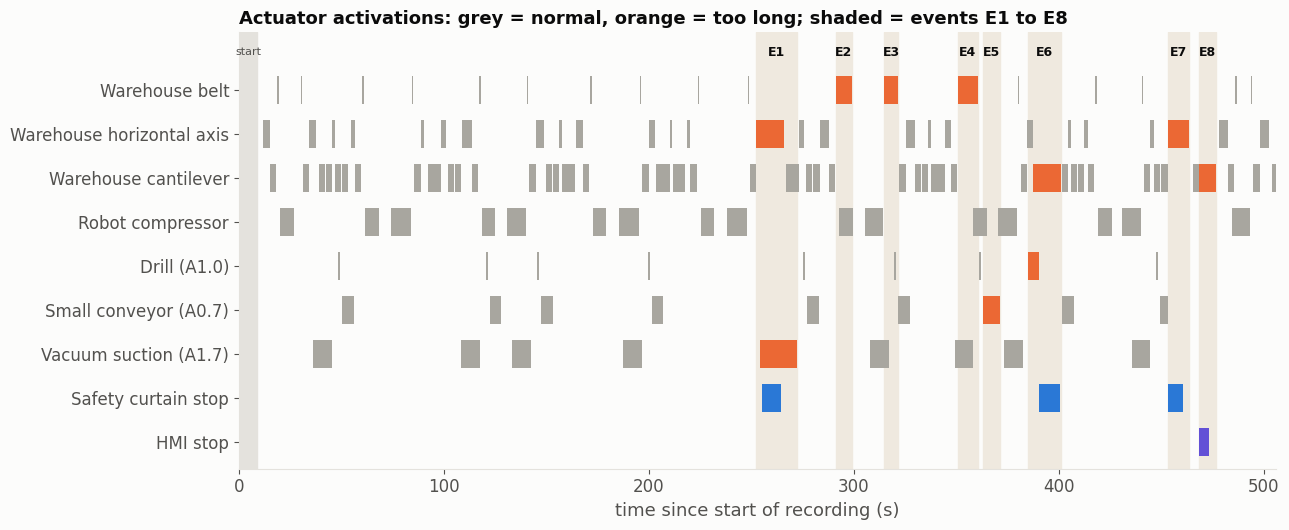

In [31]:
ROWS = [
    ("Warehouse belt", "Beckhoff",
     ["WH.Q1_beltForward", "WH.Q2_beltBackward"]),
    ("Warehouse horizontal axis", "Beckhoff",
     ["WH.Q3_horRack", "WH.Q4_horBelt"]),
    ("Warehouse cantilever", "Beckhoff",
     ["WH.Q7_cantForw", "WH.Q8_cantBack"]),
    ("Robot compressor", "Beckhoff", ["VG.Q7_compressorON"]),
    ("Drill (A1.0)", "Siemens", ["A1.0"]),
    ("Small conveyor (A0.7)", "Siemens", ["A0.7"]),
    ("Vacuum suction (A1.7)", "Siemens", ["A1.7"]),
]
fig, ax = plt.subplots(figsize=(13, 5.4))
labels = [r[0] for r in ROWS] + ["Safety curtain stop", "HMI stop"]
for y, (label, plc, signals) in enumerate(ROWS):
    part = acts[acts["signal"].isin(signals)]
    for _, a in part.iterrows():
        flagged = (a["signal"], a["start"]) in flag_keys
        ax.broken_barh([(a["start"], a["duration"])], (y - 0.32, 0.64),
                       facecolors=C_FLAG if flagged else C_NORMAL)
for y, prefix, colour in ((len(ROWS), "Safety", C_SAFETY),
                          (len(ROWS) + 1, "HMI", C_HMI)):
    part = causes[causes["cause"].str.startswith(prefix)]
    ax.broken_barh(list(zip(part["start"], part["duration"])),
                   (y - 0.32, 0.64), facecolors=colour)
for _, ev in events.iterrows():
    ax.axvspan(ev["start_s"], ev["end_s"], color="#efe9df", zorder=0)
    ax.text((ev["start_s"] + ev["end_s"]) / 2, -0.85, ev["event"],
            ha="center", va="center", fontsize=9, fontweight="bold")
ax.axvspan(0, PRODUCTION_START, color=GRID, zorder=0)
ax.text(PRODUCTION_START / 2, -0.85, "start", ha="center", va="center",
        fontsize=8, color=INK_2)
ax.set_yticks(range(len(labels)))
ax.set_yticklabels(labels)
ax.set_ylim(len(labels) - 0.4, -1.3)
ax.set_xlim(0, RECORDING_END)
ax.set_xlabel("time since start of recording (s)")
ax.set_title("Actuator activations: grey = normal, orange = too long; "
             "shaded = events E1 to E8", loc="left")
fig.tight_layout()
plt.show()

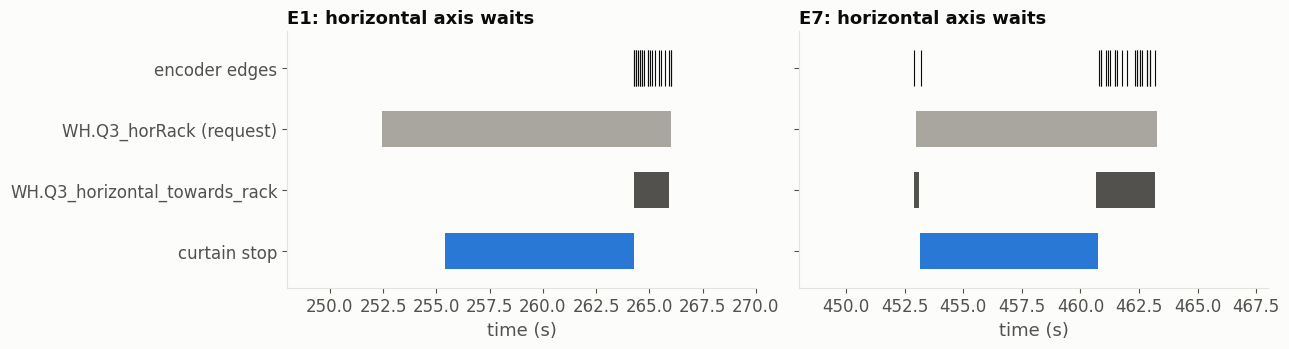

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6), sharey=True)
panels = [(248, 270, "E1"), (448, 468, "E7")]
for ax, (lo, hi, name) in zip(axes, panels):
    tracks = [
        ("WH.Q3_horRack", bec["WH.Q3_horRack"], C_NORMAL),
        ("WH.Q3_horizontal_towards_rack",
         bec["WH.Q3_horizontal_towards_rack"], INK_2),
        ("Safety curtain stop", ~sie["A201.0"].astype(bool), C_SAFETY),
    ]
    for y, (label, signal, colour) in enumerate(tracks):
        times = sie["t"] if label.startswith("Safety") else bec["t"]
        spans = [(s, e - s) for s, e in on_intervals(times, signal)
                 if overlap(s, e, lo, hi)]
        ax.broken_barh(spans, (y + 1 - 0.3, 0.6), facecolors=colour)
    window = pulse_times[(pulse_times >= lo) & (pulse_times <= hi)]
    ax.vlines(window, -0.3, 0.3, color=INK, linewidth=0.8)
    ax.set_xlim(lo, hi)
    ax.set_title(f"{name}: horizontal axis waits", loc="left")
    ax.set_xlabel("time (s)")
axes[0].set_yticks(range(4))
axes[0].set_yticklabels(["encoder edges", "WH.Q3_horRack (request)",
                         "WH.Q3_horizontal_towards_rack", "curtain stop"])
axes[0].set_ylim(3.6, -0.6)
fig.tight_layout()
plt.show()

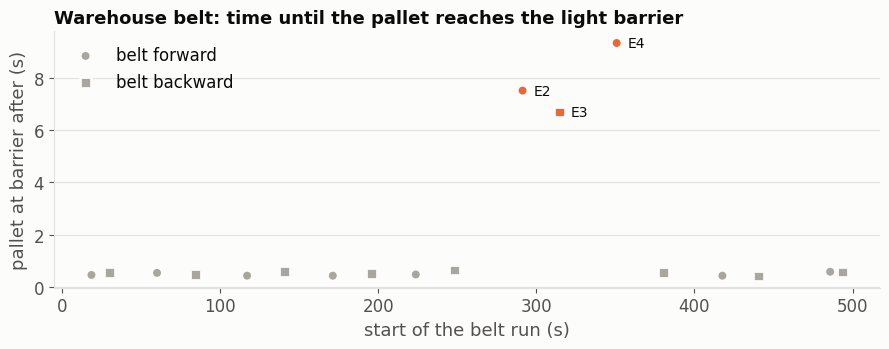

In [33]:
fig, ax = plt.subplots(figsize=(9, 3.6))
for signal, marker, label in (("WH.Q1_beltForward", "o", "belt forward"),
                              ("WH.Q2_beltBackward", "s", "belt backward")):
    part = belt[belt["signal"] == signal]
    colours = [C_FLAG if f else C_NORMAL for f in part["flagged"]]
    ax.scatter(part["start"], part["barrier_reached_after_s"], s=60,
               c=colours, marker=marker, edgecolors="#fcfcfb",
               linewidths=2, label=label)
for _, b in belt[belt["flagged"]].iterrows():
    name = flags.loc[flags["start"] == b["start"], "event"].iloc[0]
    ax.annotate(name, (b["start"], b["barrier_reached_after_s"]),
                xytext=(8, 0), textcoords="offset points", va="center")
ax.set_xlabel("start of the belt run (s)")
ax.set_ylabel("pallet at barrier after (s)")
ax.set_title("Warehouse belt: time until the pallet reaches the light "
             "barrier", loc="left")
ax.legend(frameon=False, loc="upper left")
ax.grid(axis="y", color=GRID)
fig.tight_layout()
plt.show()

## Extension 1 - How robust is the event list? (threshold sweep)

Step 4.2 varied k and the minimum excess at three values. The sweep below varies them more finely and also allows
a merge gap between flagged activations. An event that disappears at stricter settings is not dropped; it is marked
*threshold-sensitive*.

In [34]:
sweep = ctx["sweep"]
display(sweep[sweep["merge_gap_s"] == 0].pivot(index="min_excess_s", columns="tukey_k", values="events"))
print("events over the whole sweep:", sweep["events"].min(), "to", sweep["events"].max())
ctx["events"][["event", "signals", "sweep_presence", "existence_confidence"]]

tukey_k,1.5,3.0
min_excess_s,,
1.00,16,10
1.50,8,8
1.84,8,8
2.00,8,8
2.50,7,7
3.00,7,7
4.00,7,7
5.00,6,6


events over the whole sweep: 6 to 16


,event,signals,sweep_presence,existence_confidence
0,E1,WH.Q3_horRack A1.7,1.000,high
1,E2,WH.Q1_beltForward,1.000,high
2,E3,WH.Q2_beltBackward,1.000,high
3,E4,WH.Q1_beltForward,1.000,high
4,E5,A0.7,0.500,medium
5,E6,A1.0 WH.Q7_cantForw,1.000,high
6,E7,WH.Q3_horRack,1.000,high
7,E8,WH.Q8_cantBack,0.875,medium


## Robustness: clock shift and time grid

**Clock shift.** Event detection compares durations *within* one PLC, so a clock offset can only shift cross-PLC
timing statements. Test: shift the Beckhoff clock on purpose by up to 1 s (25 times the bound of notebook 03) and
re-run preparation + detection.

**Time grid.** Both recordings are put on regular grids (forward fill, the rule of the team's 50 ms merge) and the
same preparation + detection runs with the frozen parameters.

**Re-run on a shifted or gridded copy of the data**

- `interval_table`: Like ``on_intervals`` but also marks periods cut by the recording borders.
- `recording_end`: Last logged time of either PLC.
- `production_start`: First press of the documented HMI reset button (E200.0).
- `stop_windows`: Protective (curtain) stops and HMI stops, with their confirmations.
- `pallet_cycles`: A pallet cycle starts at every change of the requested rack position.
- `actuator_lists`: Actuator outputs used for activation analysis (documented / IEC naming).
- `station_of`: Station of a signal according to the variable file.
- `activations`: One row per ON-period of each actuator output (station activity).
- `mark_stop_cuts`: Flag activations truncated by a stop, or restarted right after one.

In [35]:
def interval_table(t, x) -> pd.DataFrame:
    """Like ``on_intervals`` but also marks periods cut by the recording borders."""
    t = np.asarray(t, dtype=float)
    x = np.asarray(x, dtype=bool).astype(int)
    change = np.diff(np.concatenate(([0], x, [0])))
    starts = np.flatnonzero(change == 1)
    ends_idx = np.flatnonzero(change == -1)
    out = pd.DataFrame({
        "start": t[starts],
        "end": t[np.minimum(ends_idx, len(t) - 1)],
        "open_at_start": starts == 0,
        "open_at_end": ends_idx >= len(t),
        "start_idx": starts,
        "end_idx": np.minimum(ends_idx, len(t) - 1),
    })
    out["duration"] = out["end"] - out["start"]
    return out


def recording_end(data: dict) -> float:
    return float(max(data["Siemens"].frame["t"].iloc[-1], data["Beckhoff"].frame["t"].iloc[-1]))


def production_start(data: dict, cfg: dict) -> float:
    """First press of the documented HMI reset button (E200.0)."""
    s = data["Siemens"].frame
    presses = on_intervals(s["t"], s[cfg["phases"]["production_start_signal"]])
    return presses[0][0]


def stop_windows(data: dict, cfg: dict, sync_tol_s: float) -> pd.DataFrame:
    """Protective (curtain) stops and HMI stops, with their confirmations."""
    s, b = data["Siemens"].frame, data["Beckhoff"].frame
    ph = cfg["phases"]
    p0 = production_start(data, cfg)
    presses = hmi_reset_times(data, cfg)
    lamp = on_intervals(s["t"], s["M0.3"])
    sr_long = on_intervals(s["t"], s["M24.3"])
    bec_curtain = on_intervals(b["t"], ~b[ph["curtain_signal_beckhoff"]].astype(bool))
    rows = []

    def matched(a, e, windows):
        return any(abs(x - a) <= sync_tol_s and abs(y - e) <= sync_tol_s for x, y in windows)

    for a, e in on_intervals(s["t"], ~s[ph["curtain_signal"]].astype(bool)):
        reset = min(presses, key=lambda r: abs(r - e))
        rows.append({
            "kind": "protective stop (light curtain)" if a >= p0 else "start-up (curtain not yet reset)",
            "start_s": a, "end_s": e, "duration_s": e - a,
            "source_signal": f"Siemens {ph['curtain_signal']} LOW",
            "confirm_red_lamp_M0.3": matched(a, e, lamp),
            "confirm_long_curtain_SR_M24.3": matched(a, e, sr_long),
            "confirm_beckhoff_receiver": matched(a, e, bec_curtain),
            "ended_by_reset_press": abs(reset - e) <= sync_tol_s,
            "reset_press_s": reset,
        })
    stoplight = on_intervals(b["t"], b["Visual.Stoplight"])
    for a, e in on_intervals(b["t"], ~b[ph["hmi_run_signal"]].astype(bool)):
        rows.append({
            "kind": "HMI stop", "start_s": a, "end_s": e, "duration_s": e - a,
            "source_signal": f"Beckhoff {ph['hmi_run_signal']} LOW",
            "confirm_red_lamp_M0.3": False, "confirm_long_curtain_SR_M24.3": False,
            "confirm_beckhoff_receiver": matched(a, e, stoplight),
            "ended_by_reset_press": False, "reset_press_s": np.nan,
        })
    out = pd.DataFrame(rows).sort_values("start_s").reset_index(drop=True)
    out.insert(0, "stop_id", [f"S{i}" for i in range(len(out))])
    return out


def pallet_cycles(data: dict, cfg: dict) -> pd.DataFrame:
    """A pallet cycle starts at every change of the requested rack position."""
    b = data["Beckhoff"].frame
    req = cfg["phases"]["pallet_request_signals"]
    new = b[req].diff().ne(0).any(axis=1)
    cyc = b.loc[new, ["t"] + req].reset_index(drop=True)
    cyc.columns = ["start_s", "rack_x", "rack_y"]
    cyc.insert(0, "cycle", range(1, len(cyc) + 1))
    cyc["end_s"] = np.r_[cyc["start_s"].to_numpy()[1:], recording_end(data)]
    cyc["duration_s"] = cyc["end_s"] - cyc["start_s"]
    p0 = production_start(data, cfg)
    last = cyc["cycle"].max()
    s = data["Siemens"].frame
    oven_in = [a for a, _ in on_intervals(s["t"], s["A1.1"])]
    robot = [a for a, _ in on_intervals(b["t"], b["VG.Q7_compressorON"])]
    belt_f = [a for a, _ in on_intervals(b["t"], b["WH.Q1_beltForward"])]
    belt_b = [a for a, _ in on_intervals(b["t"], b["WH.Q2_beltBackward"])]

    def count(times, a, e):
        return int(sum(a <= x < e for x in times))

    cyc["robot_moves"] = [count(robot, a, e) for a, e in zip(cyc["start_s"], cyc["end_s"])]
    cyc["belt_forward"] = [count(belt_f, a, e) for a, e in zip(cyc["start_s"], cyc["end_s"])]
    cyc["belt_backward"] = [count(belt_b, a, e) for a, e in zip(cyc["start_s"], cyc["end_s"])]
    cyc["oven_runs"] = [count(oven_in, a, e) for a, e in zip(cyc["start_s"], cyc["end_s"])]
    roles = []
    for _, c in cyc.iterrows():
        if c["start_s"] < p0:
            roles.append("start-up (contains homing; first part only)")
        elif c["cycle"] == last:
            roles.append("final (truncated by end of recording; no new part)")
        else:
            roles.append("complete")
    cyc["role"] = roles
    cyc["complete"] = cyc["role"] == "complete"
    return cyc


def actuator_lists(data: dict) -> dict:
    """Actuator outputs used for activation analysis (documented / IEC naming)."""
    sdoc = data["doc"]["Siemens"]
    sie = sdoc.loc[sdoc["signal"].str.match(r"^A\d") &
                   sdoc["station"].isin(["Sorting station", "Drilling station"]), "signal"].tolist()
    bec = [c for c in data["Beckhoff"].signals if ".Q" in c]
    return {"Siemens": sie, "Beckhoff": bec}


def station_of(data: dict, plc: str, signal: str) -> str:
    doc = data["doc"][plc].set_index("signal")
    return doc.loc[signal, "station"] if signal in doc.index else ""


def activations(data: dict, cfg: dict, cycles: pd.DataFrame) -> pd.DataFrame:
    """One row per ON-period of each actuator output (station activity)."""
    p0 = production_start(data, cfg)
    acts = actuator_lists(data)
    frames = []
    for plc, signals in acts.items():
        d = data[plc].frame
        for sig in signals:
            it = interval_table(d["t"], d[sig])
            if it.empty:
                continue
            it.insert(0, "signal", sig)
            it.insert(0, "plc", plc)
            it["station"] = station_of(data, plc, sig)
            frames.append(it)
    out = pd.concat(frames, ignore_index=True)
    out["in_production"] = out["start"] >= p0
    starts = cycles["start_s"].to_numpy()
    out["cycle"] = np.searchsorted(starts, out["start"].to_numpy(), side="right")
    out["cycle"] = out["cycle"].clip(lower=1)
    return out.sort_values(["start", "plc", "signal"]).reset_index(drop=True)


def mark_stop_cuts(acts: pd.DataFrame, stops: pd.DataFrame) -> pd.DataFrame:
    """Flag activations truncated by a stop, or restarted right after one."""
    a = acts.copy()
    a["cut_by_stop"] = [cut_by_stop(s, e, stops) for s, e in zip(a["start"], a["end"])]
    a["resumed_after_stop"] = [resumed_after_stop(s, stops) for s in a["start"]]
    return a

- `grid_bundle`: Copy of the data bundle with every PLC frame on a regular grid.
- `_events`: Events (start, end, lost time, signals) from flagged activations.
- `run_on`: Accepted preparation + Model-1 detection on a (possibly gridded) bundle.
- `event_sensitivity`: Compare the raw-time result with the result on each regular grid.

In [36]:
def grid_bundle(data: dict, grid_ms: int) -> dict:
    """Copy of the data bundle with every PLC frame on a regular grid.

    The value at a grid tick is the last logged row at or before that tick
    (forward fill). Nothing is interpolated: boolean states cannot be averaged.
    """
    out = dict(data)
    step = grid_ms / 1000.0
    for plc in ("Siemens", "Beckhoff"):
        d = data[plc]
        f = d.frame
        ticks = np.arange(f["t"].iloc[0], f["t"].iloc[-1] + 1e-9, step)
        pos = np.searchsorted(f["t"].to_numpy(), ticks, side="right") - 1
        g = f.iloc[pos].reset_index(drop=True).copy()
        g["t"] = ticks
        g["timestamp"] = (data["t0_ms"] + np.round(ticks * 1000)).astype("int64")
        out[plc] = dataclasses.replace(d, frame=g)
    return out


def _events(flags: pd.DataFrame) -> pd.DataFrame:
    if flags.empty:
        return pd.DataFrame(columns=["start_s", "end_s", "lost_s", "signals"])
    return (flags.groupby("event")
            .agg(start_s=("start", "min"), end_s=("end", "max"), lost_s=("excess", "max"),
                 signals=("signal", lambda s: " ".join(sorted(s))))
            .reset_index(drop=True))


def run_on(data: dict, cfg: dict, min_excess_s: float, tol: float) -> dict:
    """Accepted preparation + Model-1 detection on a (possibly gridded) bundle."""
    rc = cfg["rule"]
    stops = stop_windows(data, cfg, tol)
    cycles = pallet_cycles(data, cfg)
    acts = mark_stop_cuts(activations(data, cfg, cycles), stops)
    flags, _ = detect(acts, rc["tukey_k"], min_excess_s, rc["min_activations"], rc["merge_gap_s"])
    return {"stops": stops, "cycles": cycles, "acts": acts, "events": _events(flags), "flags": flags}


def event_sensitivity(data: dict, cfg: dict, raw: dict, grids_ms: list[int], min_excess_s: float,
                      tol: float, event_names: list[str]) -> pd.DataFrame:
    """Compare the raw-time result with the result on each regular grid.

    ``raw`` is ``run_on(data, ...)``; ``event_names`` labels its events (E1..).
    Columns: what is lost or shifted by the grid at every level of the analysis
    (rows, stop windows, cycles, flagged activations, events, lost time, equipment).
    """
    rev = raw["events"].reset_index(drop=True).copy()
    rev["event"] = event_names
    rstops, rcyc = raw["stops"], raw["cycles"]
    rows = []
    for g in grids_ms:
        row = {"grid_ms": g}
        try:
            res = run_on(grid_bundle(data, g), cfg, min_excess_s, tol)
        except Exception as exc:                  # a grid can lose a pulse the pipeline needs
            row["status"] = f"failed: {type(exc).__name__}: {exc}"
            rows.append(row)
            continue
        ev = res["events"]
        matched, lost_diff, same_equipment = [], [], []
        for r in rev.itertuples():
            hit = ev[[overlaps(r.start_s, r.end_s, a, b) for a, b in zip(ev["start_s"], ev["end_s"])]]
            if len(hit):
                matched.append(r.event)
                lost_diff.append(abs(hit["lost_s"].max() - r.lost_s))
                same_equipment.append(set(" ".join(hit["signals"]).split()) == set(r.signals.split()))
        extra = sum(not any(overlaps(a, b, x, y) for x, y in zip(rev["start_s"], rev["end_s"]))
                    for a, b in zip(ev["start_s"], ev["end_s"]))
        st = res["stops"]
        stop_shift = (max(abs(st["start_s"].to_numpy() - rstops["start_s"].to_numpy()).max(),
                          abs(st["end_s"].to_numpy() - rstops["end_s"].to_numpy()).max())
                      if len(st) == len(rstops) else np.nan)
        cyc = res["cycles"]
        cyc_shift = (abs(cyc["duration_s"].to_numpy() - rcyc["duration_s"].to_numpy()).max()
                     if len(cyc) == len(rcyc) else np.nan)
        row.update({
            "status": "ok",
            "flagged_activations": int(len(res["flags"])), "events": int(len(ev)),
            "raw_events_found": " ".join(matched),
            "raw_events_missed": " ".join(e for e in rev["event"] if e not in matched),
            "extra_events": int(extra),
            "max_lost_time_change_s": float(max(lost_diff)) if lost_diff else np.nan,
            "same_equipment_flagged": bool(all(same_equipment)) if same_equipment else False,
            "stop_windows": int(len(st)), "max_stop_boundary_shift_s": stop_shift,
            "pallet_cycles": int(len(cyc)), "max_cycle_duration_change_s": cyc_shift,
        })
        rows.append(row)
    return pd.DataFrame(rows)

In [37]:
import dataclasses
raw = run_on(data, cfg, ctx["min_excess"], ctx["tol"])
rows = []
for shift in (-1.0, -0.5, -0.1, 0.1, 0.5, 1.0):
    d = dict(data)
    f = data["Beckhoff"].frame.copy()
    f["t"] = f["t"] + shift
    d["Beckhoff"] = dataclasses.replace(data["Beckhoff"], frame=f)
    ev = run_on(d, cfg, ctx["min_excess"], ctx["tol"])["events"]
    found = sum(any(overlaps(a, b, x, y) for x, y in zip(ev["start_s"], ev["end_s"]))
                for a, b in zip(raw["events"]["start_s"], raw["events"]["end_s"]))
    rows.append({"beckhoff_shift_s": shift, "events": len(ev), "raw_events_found": found})
pd.DataFrame(rows)

,beckhoff_shift_s,events,raw_events_found
0,-1.0,8,8
1,-0.5,8,8
2,-0.1,8,8
3,0.1,8,8
4,0.5,8,8
5,1.0,8,8


In [38]:
grid = event_sensitivity(data, cfg, raw, cfg["timebase"]["resample_grids_ms"], ctx["min_excess"], ctx["tol"],
                         list(ctx["events"]["event"]))
ok = grid[grid["grid_ms"] <= 200]
assert (ok["events"] == len(raw["events"])).all() and (ok["extra_events"] == 0).all() and ok["same_equipment_flagged"].all()
grid[["grid_ms", "flagged_activations", "events", "raw_events_missed", "extra_events", "max_lost_time_change_s",
      "same_equipment_flagged", "max_stop_boundary_shift_s", "max_cycle_duration_change_s"]].round(3)

,grid_ms,flagged_activations,events,raw_events_missed,extra_events,max_lost_time_change_s,same_equipment_flagged,max_stop_boundary_shift_s,max_cycle_duration_change_s
0,20,10,8,,0,0.017,True,0.019,0.032
1,50,10,8,,0,0.037,True,0.049,0.062
2,76,10,8,,0,0.067,True,0.059,0.144
3,93,10,8,,0,0.101,True,0.077,0.083
4,100,10,8,,0,0.133,True,0.063,0.112
5,200,10,8,,0,0.233,True,0.162,0.212
6,500,11,9,E7,2,0.503,True,0.459,0.722


**Result:** even a 1 s clock shift leaves every event in place. On grids up to 200 ms the events, their equipment and
the stop windows are the same as on raw rows (lost times shift by a few hundredths of a second); at 500 ms an event
is lost and false events appear. The team's 50 ms grid is therefore confirmed, and the analysis keeps the raw rows.

## Extension 2 - Physical attribution

For every event: the first deviation, the expected versus the observed transition, the component and separate
confidences for *where* (location) and *why* (root cause).

In [39]:
ctx["attr"][["event", "first_deviation", "expected_transition", "observed", "component",
             "location_confidence", "root_cause", "root_cause_confidence"]]

,event,first_deviation,expected_transition,observed,component,location_confidence,root_cause,root_cause_confidence
0,E1,WH.Q3_horRack abnormal 2.97 s before the stop ...,motor output follows the request within 0.26 s,motor output OFF for 11.84 s (252.42-264.26 s)...,Warehouse (WH.Q3_horRack) - abnormal before th...,low,protective stop by the light curtain (document...,high for the stop mechanism; trigger unknown
1,E2,WH.Q1_beltForward passed its normal 0.86 s at ...,pallet reaches the belt light barrier within 0...,reached after 7.51 s; belt ON 7.80 s,Warehouse (WH.Q1_beltForward),high,"unknown - no stop, alarm or interlock signal i...",n/a
2,E3,WH.Q2_beltBackward passed its normal 0.57 s at...,pallet reaches the belt light barrier within 0...,reached after 6.70 s; belt ON 6.79 s,Warehouse (WH.Q2_beltBackward),high,"unknown - no stop, alarm or interlock signal i...",n/a
3,E4,WH.Q1_beltForward passed its normal 0.86 s at ...,pallet reaches the belt light barrier within 0...,reached after 9.34 s; belt ON 9.62 s,Warehouse (WH.Q1_beltForward),high,"unknown - no stop, alarm or interlock signal i...",n/a
4,E5,A0.7 passed its normal 5.77 s at 368.87 s,part at light barrier E1.0 within 1.00 s,part at E1.0 after 2.56 s,Drilling station (A0.7),high,"unknown - no stop, alarm or interlock signal i...",n/a
5,E6,A1.0 passed its normal 0.99 s at 386.06 s,drill OFF after its normal 0.99 s (drill timer...,"drill ON 5.07 s, switched off only when the st...",Drilling station (A1.0) - abnormal before the ...,medium,protective stop by the light curtain (document...,high for the stop mechanism; trigger unknown
6,E7,small conveyor A0.7 ran 3.73 s without the par...,motor output follows the request within 0.26 s,motor output OFF for 7.58 s (453.09-460.68 s) ...,Drilling station (A0.7) - abnormal before the ...,medium,protective stop by the light curtain (document...,high for the stop mechanism; trigger unknown
7,E8,HMI stop began at 468.55 s,motor output follows the request within 0.26 s,motor output OFF for 4.89 s (468.45-473.34 s) ...,Drilling -> sorting transfer (small conveyor A...,medium,operator stop at the HMI; part moved through t...,medium (manual handling is an inference from b...


## Extension 3 - Candidates rejected by the rule

Runs above the Tukey fence but less than the detection limit longer than normal. They are not counted as losses: a
single logging gap could explain them.

In [40]:
mild = ctx["mild"]
print(f"{len(mild)} runs above the fence but below the detection limit; "
      f"{int(mild['excess_beyond_uncertainty'].sum())} of them exceed their own edge uncertainty")
mild[["plc", "signal", "start", "duration", "median", "excess", "edge_uncertainty_s"]].round(2)

8 runs above the fence but below the detection limit; 3 of them exceed their own edge uncertainty


,plc,signal,start,duration,median,excess,edge_uncertainty_s
5,Beckhoff,WH.Q5_verDown,10.45,1.56,0.45,1.12,0.19
28,Siemens,A1.1,28.42,3.35,1.97,1.38,1.80
29,Siemens,A1.3,28.42,7.61,7.47,0.14,0.21
30,Siemens,A0.1,29.90,1.87,0.52,1.35,1.81
260,Beckhoff,VG.Q5_rotClockwise,182.67,1.74,1.09,0.64,0.57
390,Beckhoff,WH.Q8_cantBack,280.21,3.24,3.11,0.12,0.19
597,Siemens,A1.2,431.95,2.30,2.02,0.28,0.43
645,Beckhoff,WH.Q5_verDown,476.48,1.66,0.45,1.21,0.35


## Extension 4 - H9: reduced speed

Reduced speed = the machine moves, but slower. It is tested where a step's duration is set by motion: warehouse
horizontal travel (should be linear in distance), robot moves (same type and lane -> same duration) and drift of any
repeated step over the recording (Spearman test, Holm-corrected).

travel time = 0.005 s + distance / 532 units/s; R^2 = 0.9977, largest residual 0.14 s (n = 24)


,move_type,lane,count,median,min,max,range_s
0,lane -> pallet,blue,3,9.67,9.66,9.79,0.13
1,lane -> pallet,red,3,9.22,9.13,9.28,0.15
2,lane -> pallet,white,2,8.84,8.82,8.85,0.02
3,pallet -> oven,,8,6.65,6.62,6.72,0.10


repeated steps tested for drift: 38 | with drift: 0


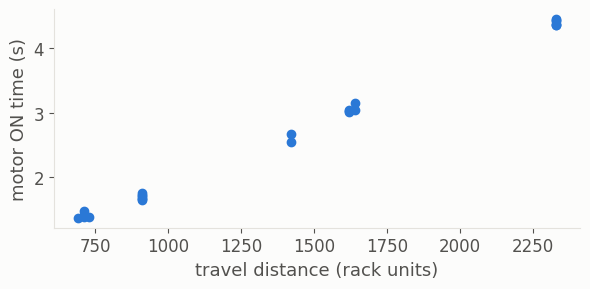

In [41]:
travel, fit = ctx["travel"], ctx["travel"].attrs["fit"]
print(f"travel time = {fit['intercept_s']:.3f} s + distance / {fit['speed_units_per_s']:.0f} units/s; "
      f"R^2 = {fit['r2']:.4f}, largest residual {fit['max_abs_residual_s']:.2f} s (n = {fit['n']})")
ok = travel[travel["used_in_fit"]]
plt.figure(figsize=(6, 3)); plt.scatter(ok["distance"], ok["duration_s"], color="#2a78d6")
plt.xlabel("travel distance (rack units)"); plt.ylabel("motor ON time (s)"); plt.tight_layout()
display(ctx["robot"].round(2))
print("repeated steps tested for drift:", len(ctx["disp"]), "| with drift:", int(ctx["disp"]["drift_detected"].sum()))

**H9 not supported** if travel follows the line, robot moves repeat and no step drifts: reduced speed was looked for
and not found as a separate loss. The belt / small-conveyor overruns stay "stop or slow, not separable".

## Figures for the report

Saved to `reports/figures/`; every title states the takeaway.

**Figure functions**

- `PLAIN`: Plain names of the signals shown in the figures.
- `MOTOR_OF`: Motor output belonging to each request output.
- `_title`: Takeaway title of a figure.
- `_save`: Save a figure at the shared resolution.
- `_on_spans`: (start, length) of every ON period of boolean x on time axis t.
- `_event_label`: 'E6' + the equipment excess of each overrun of that event (never added).
- `_note_panel`: Side panel with the 'expected vs observed' note.
- `event_timeline`: F1: the events on one strip over the production window.
- `attribution_bars`: F2: equipment excess per overrun, grouped by station.
- `_signal_rows`: Draw ON periods of a few signals as rows.
- `evidence_stop`: F4: evidence of one line-wide stop (request, motor, encoder, curtain).
- `evidence_overrun`: F4: evidence of one step overrun (output and light barriers).
- `robustness`: F5: threshold sweep and time-grid test.
- `process_flow`: Material flow of one pallet cycle with median step times.
- `travel_figure`: Warehouse axis travel time against distance.
- `event_trace`: Trace of the signals around one event.

In [42]:
# Plain names of the signals shown in the figures
PLAIN = {
    "WH.Q3_horRack": "Warehouse axis to rack (request)",
    "WH.Q3_horizontal_towards_rack": "Warehouse axis to rack (motor)",
    "WH.Q1_beltForward": "Warehouse belt outwards",
    "WH.Q2_beltBackward": "Warehouse belt inwards",
    "WH.Q7_cantForw": "Cantilever forward (request)",
    "WH.Q7_cantilever_forward": "Cantilever forward (motor)",
    "WH.Q8_cantBack": "Cantilever backward (request)",
    "WH.Q8_cantilever_backward": "Cantilever backward (motor)",
    "WH.I2_Light_barrier_inside": "Belt light barrier inside",
    "WH.I3_Light_barrier_outside": "Belt light barrier outside",
    "A1.7": "Drilling vacuum suction",
    "A1.0": "Drill",
    "A0.7": "Small conveyor",
    "E1.0": "Small-conveyor barrier (part)",
    "A201.0": "Safety curtain stop",
    "Visual.start": "HMI stop",
}


MOTOR_OF = {"WH.Q3_horRack": "WH.Q3_horizontal_towards_rack", "WH.Q7_cantForw": "WH.Q7_cantilever_forward",
            "WH.Q8_cantBack": "WH.Q8_cantilever_backward"}


def _title(fig, text):
    fig.suptitle(text, x=0.01, ha="left", fontsize=15, fontweight="bold")


def _save(fig, path):
    fig.savefig(path, dpi=DPI)
    plt.close(fig)


def _on_spans(t, x):
    """(start, length) of every ON period of boolean x on time axis t."""
    t = np.asarray(t, dtype=float)
    x = np.asarray(x, dtype=bool).astype(int)
    change = np.diff(np.concatenate(([0], x, [0])))
    starts = np.flatnonzero(change == 1)
    ends = np.minimum(np.flatnonzero(change == -1), len(t) - 1)
    return [(float(t[a]), float(t[b] - t[a])) for a, b in zip(starts, ends)]


def _event_label(event, eq):
    """'E6' + the equipment excess of each overrun of that event (never added)."""
    vals = eq.loc[eq["event"] == event, "excess_s"]
    return f"{event}\n" + " / ".join(f"{v:.1f}" for v in vals) + " s"


def _note_panel(ax, text):
    ax.axis("off")
    ax.text(0.0, 0.5, text, fontsize=12, va="center", ha="left", transform=ax.transAxes, linespacing=1.5,
            bbox={"fc": COLORS["light"], "ec": COLORS["muted"], "boxstyle": "round,pad=0.6"})


def event_timeline(events, stops, eq, p0, end, path):
    fig, ax = plt.subplots(figsize=FIGSIZE, layout="constrained")
    y0, y1 = 0.0, 1.0
    ax.axvspan(0, p0, color=COLORS["light"], zorder=0)
    ax.text(p0 + 3, 0.5, "start-up\n(excluded)", ha="left", va="center", fontsize=12, color=COLORS["muted"])
    for s in stops[stops["start_s"] >= p0].itertuples():
        ax.fill_between([s.start_s, s.end_s], y0, y1, color=COLORS["stop"], lw=0, zorder=2)
    over = events[events["stop_mechanism"].str.startswith("step overrun")]
    for e in over.itertuples():
        ax.fill_between([e.overrun_start_s, e.overrun_end_s], y0, y1, color=COLORS["overrun"], lw=0, zorder=2)
    last, top = {}, 0
    for e in events.sort_values("overrun_start_s").itertuples():
        x = (e.overrun_start_s + e.overrun_end_s) / 2
        lvl = 0
        while lvl in last and x - last[lvl] < 48:
            lvl += 1
        last[lvl] = x
        top = max(top, lvl)
        ax.annotate(_event_label(e.event, eq), (x, y1), xytext=(x, y1 + 0.35 + 0.95 * lvl), ha="center",
                    va="bottom", fontsize=12, fontweight="bold",
                    arrowprops={"arrowstyle": "-", "color": COLORS["muted"], "lw": 1})
    ax.set_ylim(-0.1, y1 + 0.35 + 0.95 * (top + 1) + 0.2)
    ax.set_xlim(0, end)
    ax.set_yticks([])
    ax.spines["left"].set_visible(False)
    ax.set_xlabel("time since the start of the recording (s); labels = equipment excess per overrun")
    ax.legend(handles=[Patch(color=COLORS["stop"], label="line-wide stop (curtain or HMI)"),
                       Patch(color=COLORS["overrun"], label="step overrun"),
                       Patch(color=COLORS["light"], label="start-up")], loc="upper left",
              bbox_to_anchor=(0.08, 1.0), ncol=1)
    n_stop = int(len(stops[stops["start_s"] >= p0]))
    _title(fig, f"{len(events)} events in production ({p0:.2f}-{end:.2f} s): {n_stop} line-wide stops (red), "
                f"{len(over)} step overruns (amber)")
    _save(fig, path)


def attribution_bars(eq, events, path):
    mech = events.set_index("event")["stop_mechanism"]
    rows = eq.copy()
    rows["is_stop"] = ~rows["event"].map(mech).str.startswith("step overrun")
    rows = rows.sort_values(["station", "event", "order_in_incident"], ascending=[False, True, True])
    fig, ax = plt.subplots(figsize=FIGSIZE, layout="constrained")
    y, ticks, labels, group_y = 0, [], [], []
    for station, g in rows.groupby("station", sort=False):
        group_y.append((station, y))
        for r in g.itertuples():
            ax.barh(y, r.excess_s, color=COLORS["stop"] if r.is_stop else COLORS["overrun"], height=0.7)
            ax.text(r.excess_s + 0.15, y, f"{r.excess_s:.1f} s", va="center", fontsize=12)
            ticks.append(y)
            labels.append(f"{r.event}  {PLAIN.get(r.signal, r.signal)}")
            y += 1
        y += 0.8
    for station, gy in group_y:
        ax.text(-0.02, gy - 0.75, station, transform=ax.get_yaxis_transform(), ha="right", fontsize=13,
                fontweight="bold", color=COLORS["accent"])
    ax.set_yticks(ticks)
    ax.set_yticklabels(labels)
    ax.invert_yaxis()
    ax.set_xlim(0, rows["excess_s"].max() * 1.15)
    ax.set_xlabel("equipment excess over the normal (median) duration (s) - equipment seconds, not additive")
    ax.legend(handles=[Patch(color=COLORS["stop"], label="event with a line-wide stop"),
                       Patch(color=COLORS["overrun"], label="step overrun, no stop signal")], loc="lower right")
    n_st = rows.groupby("station")["event"].size().sort_values(ascending=False)
    _title(fig, "Where steps took too long: " + " and ".join(f"{n} overruns at the {s.lower()}"
                                                            for s, n in n_st.items()))
    _save(fig, path)


def _signal_rows(ax, data, rows, a, b, highlight):
    for y, (plc, sig, label, invert) in enumerate(rows):
        d = data[plc].frame
        w = d[(d["t"] >= a - 20) & (d["t"] <= b + 20)]
        if sig == "encoder":
            for enc in ("WH.B1_encoder_horizontal_impuls1", "WH.B2_encoder_horizontal_impuls2"):
                v = w[enc].to_numpy()
                e = w["t"].to_numpy()[1:][v[1:] != v[:-1]]
                ax.vlines(e[(e >= a) & (e <= b)], y - 0.3, y + 0.3, color=COLORS["navy"], lw=1)
            continue
        x = ~w[sig].astype(bool) if invert else w[sig].astype(bool)
        col = COLORS["stop"] if sig == "A201.0" else COLORS["overrun"] if sig in highlight else COLORS["accent"]
        ax.broken_barh([s for s in _on_spans(w["t"], x) if s[0] + s[1] >= a and s[0] <= b], (y - 0.3, 0.6),
                       facecolors=col)
    ax.set_yticks(range(len(rows)))
    ax.set_yticklabels([r[2] for r in rows])
    ax.set_ylim(len(rows) - 0.4, -0.6)
    ax.set_xlim(a, b)
    ax.set_xlabel("time since the start of the recording (s)")


def evidence_stop(data, events, stops, paired, path, event="E7"):
    ev = events.set_index("event").loc[event]
    st = stops.set_index("stop_id").loc[ev["stop_id"]]
    pw = paired[(paired["start_s"] <= ev["end_s"]) & (paired["end_s"] >= ev["start_s"])
                & (paired["request"] == "WH.Q3_horRack")].iloc[0]
    a, b = ev["start_s"] - 3, ev["end_s"] + 3
    rows = [("Beckhoff", "WH.Q3_horRack", "Axis request", False),
            ("Beckhoff", "WH.Q3_horizontal_towards_rack", "Axis motor output", False),
            ("Beckhoff", "encoder", "Axis encoder pulses", False),
            ("Siemens", "A201.0", "Safety curtain stop", True)]
    fig, (ax, nb) = plt.subplots(1, 2, figsize=FIGSIZE, layout="constrained", width_ratios=[2.6, 1])
    ax.axvspan(st["start_s"], st["end_s"], color=COLORS["stop"], alpha=0.12, zorder=0)
    _signal_rows(ax, data, rows, a, b, {"WH.Q3_horRack"})
    _note_panel(nb, f"Expected:\nmotor follows the request\nwithin 0.26 s\n\nObserved:\nmotor OFF for "
                    f"{pw['duration_s']:.2f} s\nwhile requested,\nencoder silent,\ninside curtain stop "
                    f"{ev['stop_id']}\n({st['duration_s']:.2f} s, shaded)")
    _title(fig, f"{event}: the axis was requested, but its motor stayed off for {pw['duration_s']:.1f} s "
                f"during curtain stop {ev['stop_id']}")
    _save(fig, path)


def evidence_overrun(data, belt, flags, path, event="E3"):
    f = flags[flags["event"] == event].iloc[0]
    sig = f["signal"]
    run = belt[(belt["signal"] == sig) & (np.isclose(belt["start"], f["start"]))].iloc[0]
    keys = set(zip(flags["signal"], flags["start"].round(6)))
    flagged = np.array([(s, round(t, 6)) in keys for s, t in zip(belt["signal"], belt["start"])])
    normal = belt[(belt["signal"] == sig).to_numpy() & ~flagged]
    a, b = f["start"] - 3, f["end"] + 3
    rows = [("Beckhoff", sig, PLAIN.get(sig, sig) + " (output)", False),
            ("Beckhoff", "WH.I2_Light_barrier_inside", PLAIN["WH.I2_Light_barrier_inside"], False),
            ("Beckhoff", "WH.I3_Light_barrier_outside", PLAIN["WH.I3_Light_barrier_outside"], False)]
    fig, (ax, nb) = plt.subplots(1, 2, figsize=FIGSIZE, layout="constrained", width_ratios=[2.6, 1])
    ax.axvspan(f["overrun_start_s"], f["overrun_end_s"], color=COLORS["overrun"], alpha=0.15, zorder=0)
    _signal_rows(ax, data, rows, a, b, {sig})
    _note_panel(nb, f"Expected:\npallet at the barrier after\n{normal['barrier_reached_after_s'].min():.2f}-"
                    f"{normal['barrier_reached_after_s'].max():.2f} s (normal runs)\n\nObserved:\n"
                    f"{run['barrier_reached_after_s']:.2f} s; belt ON {run['duration']:.2f} s\nno stop signal\n"
                    "(shaded = beyond the\nnormal duration)")
    _title(fig, f"{event}: the belt ran {run['duration']:.1f} s instead of about {normal['duration'].median():.1f} s "
                "before the pallet reached its barrier")
    _save(fig, path)


def robustness(sweep, grid, n_events, limit, path):
    fig, (a, b) = plt.subplots(1, 2, figsize=FIGSIZE, layout="constrained")
    s = sweep[sweep["merge_gap_s"] == 0.0]
    both = s.groupby("min_excess_s")["events"].apply(lambda v: (v == n_events).all())
    plateau = both[both].index
    a.axvspan(plateau.min(), plateau.max(), color=COLORS["accent"], alpha=0.15)
    a.text(plateau.max() + 0.1, n_events + 1.2, f"{n_events} events for\n{plateau.min():.1f}-{plateau.max():.1f} s",
           ha="left", fontsize=12, color=COLORS["accent"], fontweight="bold")
    for k, col, m in ((1.5, COLORS["overrun"], "s"), (3.0, COLORS["navy"], "o")):
        p = s[s["tukey_k"] == k]
        a.plot(p["min_excess_s"], p["events"], marker=m, color=col, lw=2, ms=8, label=f"Tukey k = {k:g}")
    a.axvline(limit, color=COLORS["stop"], ls="--", lw=1.5)
    a.text(limit + 0.08, s["events"].max() + 0.5, f"used: {limit:.2f} s", color=COLORS["stop"], fontsize=12)
    a.set_ylim(0, s["events"].max() + 2)
    a.set_xlabel("minimum excess over the median (s)")
    a.set_ylabel("events found")
    a.legend(loc="lower right")
    a.set_title("A  Threshold sweep")
    g = grid[grid["status"] == "ok"].copy()
    missed = g["raw_events_missed"].fillna("").astype(str).str.split().str.len()
    g["found"] = n_events - missed
    xs = np.arange(len(g))
    b.bar(xs - 0.2, g["found"], width=0.4, color=COLORS["accent"], label=f"events found (of {n_events})")
    b.bar(xs + 0.2, g["extra_events"], width=0.4, color=COLORS["stop"], label="false extra events")
    for x, f, e in zip(xs, g["found"], g["extra_events"]):
        b.text(x - 0.2, f + 0.15, str(int(f)), ha="center", fontsize=12)
        b.text(x + 0.2, e + 0.15, str(int(e)), ha="center", fontsize=12)
    b.set_xticks(xs)
    b.set_xticklabels([f"{int(v)}" for v in g["grid_ms"]])
    b.set_xlabel("regular time grid (ms)")
    b.set_ylabel("events")
    b.set_ylim(0, n_events + 3.5)
    b.legend(loc="upper left", ncol=2)
    b.set_title("B  Time-grid test")
    ok_to = int(g.loc[(g["found"] == n_events) & (g["extra_events"] == 0), "grid_ms"].max())
    _title(fig, f"The {n_events} events are robust: same count for thresholds {plateau.min():.1f}-"
                f"{plateau.max():.1f} s and for grids up to {ok_to} ms")
    _save(fig, path)


def process_flow(medians: dict, path):
    fig, ax = plt.subplots(figsize=FIGSIZE, layout="constrained")
    ax.set_xlim(0, 12)
    ax.set_ylim(0, 5.0)
    ax.axis("off")
    w, h = 2.55, 1.75
    boxes = [
        (0.1, 2.9, "Warehouse", f"pallet out\nbelt {medians['belt_out']:.2f} s"),
        (3.1, 2.9, "Robot move 1", f"pallet -> oven\n{medians['robot_1']:.2f} s"),
        (6.1, 2.9, "Drilling station", f"oven {medians['oven']:.2f} s\ndrill {medians['drill']:.2f} s"),
        (9.1, 2.9, "Conveyor + sorting", f"small conveyor\n{medians['conveyor']:.2f} s, lane"),
        (9.1, 0.35, "Robot move 2", f"lane -> pallet\n{medians['robot_2']:.2f} s"),
        (4.6, 0.35, "Warehouse", f"belt in {medians['belt_in']:.2f} s\nstore pallet"),
    ]
    for x, y, title, body in boxes:
        ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02,rounding_size=0.1",
                                    fc=COLORS["light"], ec=COLORS["accent"], lw=1.5))
        ax.text(x + w / 2, y + h - 0.35, title, ha="center", va="center", fontsize=13, fontweight="bold")
        ax.text(x + w / 2, y + 0.65, body, ha="center", va="center", fontsize=12)
    arrows = [((2.65, 3.8), (3.1, 3.8)), ((5.65, 3.8), (6.1, 3.8)), ((8.65, 3.8), (9.1, 3.8)),
              ((10.4, 2.9), (10.4, 2.1)), ((9.1, 1.2), (7.15, 1.2)), ((4.6, 1.2), (1.4, 1.2)), ((1.4, 1.2), (1.4, 2.9))]
    for p, q in arrows:
        ax.add_patch(FancyArrowPatch(p, q, arrowstyle="-|>", mutation_scale=16, color=COLORS["navy"], lw=1.5))
    ax.text(1.55, 1.95, "next pallet\nrequest", fontsize=12, color=COLORS["muted"])
    _title(fig, "One pallet cycle: a serial warehouse-robot chain (median step times in production)")
    _save(fig, path)


def travel_figure(w, path):
    fit = w.attrs["fit"]
    ok = w[w["used_in_fit"]]
    bad = w[w["cut_by_stop"] | w["resumed_after_stop"]]
    fig, ax = plt.subplots(figsize=FIGSIZE, layout="constrained")
    xs = np.linspace(0, ok["distance"].max() * 1.05, 10)
    ax.plot(xs, fit["intercept_s"] + fit["slope_s_per_unit"] * xs, color=COLORS["muted"], lw=1.5, ls="--",
            label=f"constant speed {fit['speed_units_per_s']:.0f} units/s")
    for d, m, col in (("towards rack", "o", COLORS["accent"]), ("towards belt", "s", COLORS["navy"])):
        p = ok[ok["direction"] == d]
        ax.scatter(p["distance"], p["duration_s"], s=80, marker=m, color=col, label=d, zorder=3)
    ax.scatter(bad["distance"], bad["duration_s"], s=90, marker="x", color=COLORS["stop"],
               label="cut by / resumed after a stop (not used)")
    ax.set_xlabel("travel distance (rack units)")
    ax.set_ylabel("motor ON time (s)")
    ax.legend(loc="upper left")
    _title(fig, f"Axis travel time is linear in distance (R² = {fit['r2']:.3f}, n = {fit['n']}, largest residual "
                f"{fit['max_abs_residual_s']:.2f} s): no reduced speed")
    _save(fig, path)


def event_trace(ev, flags, data, stops, mw22, eq, path, pad=6.0):
    a, b = ev["start_s"] - pad, ev["end_s"] + pad
    sigs = list(dict.fromkeys(flags.loc[flags["event"] == ev["event"], "signal"]))
    tracks = []
    for s in sigs:
        plc = "Siemens" if s in data["Siemens"].signals else "Beckhoff"
        tracks.append((plc, s, PLAIN.get(s, s), False))
        if s in MOTOR_OF:
            tracks.append(("Beckhoff", MOTOR_OF[s], PLAIN.get(MOTOR_OF[s], MOTOR_OF[s]), False))
        if s in ("WH.Q1_beltForward", "WH.Q2_beltBackward"):
            tracks += [("Beckhoff", "WH.I2_Light_barrier_inside", PLAIN["WH.I2_Light_barrier_inside"], False),
                       ("Beckhoff", "WH.I3_Light_barrier_outside", PLAIN["WH.I3_Light_barrier_outside"], False)]
    tracks += [("Siemens", "A0.7", PLAIN["A0.7"], False), ("Siemens", "E1.0", PLAIN["E1.0"], True),
               ("Siemens", "A201.0", PLAIN["A201.0"], True), ("Beckhoff", "Visual.start", PLAIN["Visual.start"], True)]
    seen, uniq = set(), []
    for t in tracks:
        if t[1] in seen:
            continue
        seen.add(t[1])
        d = data[t[0]].frame
        w = d[(d["t"] >= a) & (d["t"] <= b)]
        x = ~w[t[1]].astype(bool) if t[3] else w[t[1]].astype(bool)
        if t[1] in sigs or x.any():          # keep only rows that are ON inside the window
            uniq.append(t)
    tracks = uniq
    fig, ax = plt.subplots(figsize=FIGSIZE, layout="constrained")
    for y, (plc, s, label, invert) in enumerate(tracks):
        d = data[plc].frame
        w = d[(d["t"] >= a - 30) & (d["t"] <= b + 30)]
        x = ~w[s].astype(bool) if invert else w[s].astype(bool)
        col = (COLORS["stop"] if s in ("A201.0", "Visual.start") else
               COLORS["overrun"] if s in sigs else COLORS["accent"])
        ax.broken_barh([p for p in _on_spans(w["t"], x) if p[0] + p[1] >= a and p[0] <= b], (y - 0.3, 0.6),
                       facecolors=col)
    ax.axvspan(ev["overrun_start_s"], ev["overrun_end_s"], color=COLORS["overrun"], alpha=0.13, zorder=0)
    ax.set_yticks(range(len(tracks)))
    ax.set_yticklabels([t[2] for t in tracks])
    ax.set_ylim(len(tracks) - 0.4, -0.6)
    ax.set_xlim(a, b)
    ax.set_xlabel("time since the start of the recording (s); shaded = beyond the normal duration")
    vals = " / ".join(f"{v:.1f} s" for v in eq.loc[eq["event"] == ev["event"], "excess_s"])
    kind = "line-wide stop" if ev["loss_category"] == "minor stop" else "step overrun, stop or slow not separable"
    _title(fig, f"{ev['event']} ({kind}): equipment excess {vals}")
    _save(fig, path)

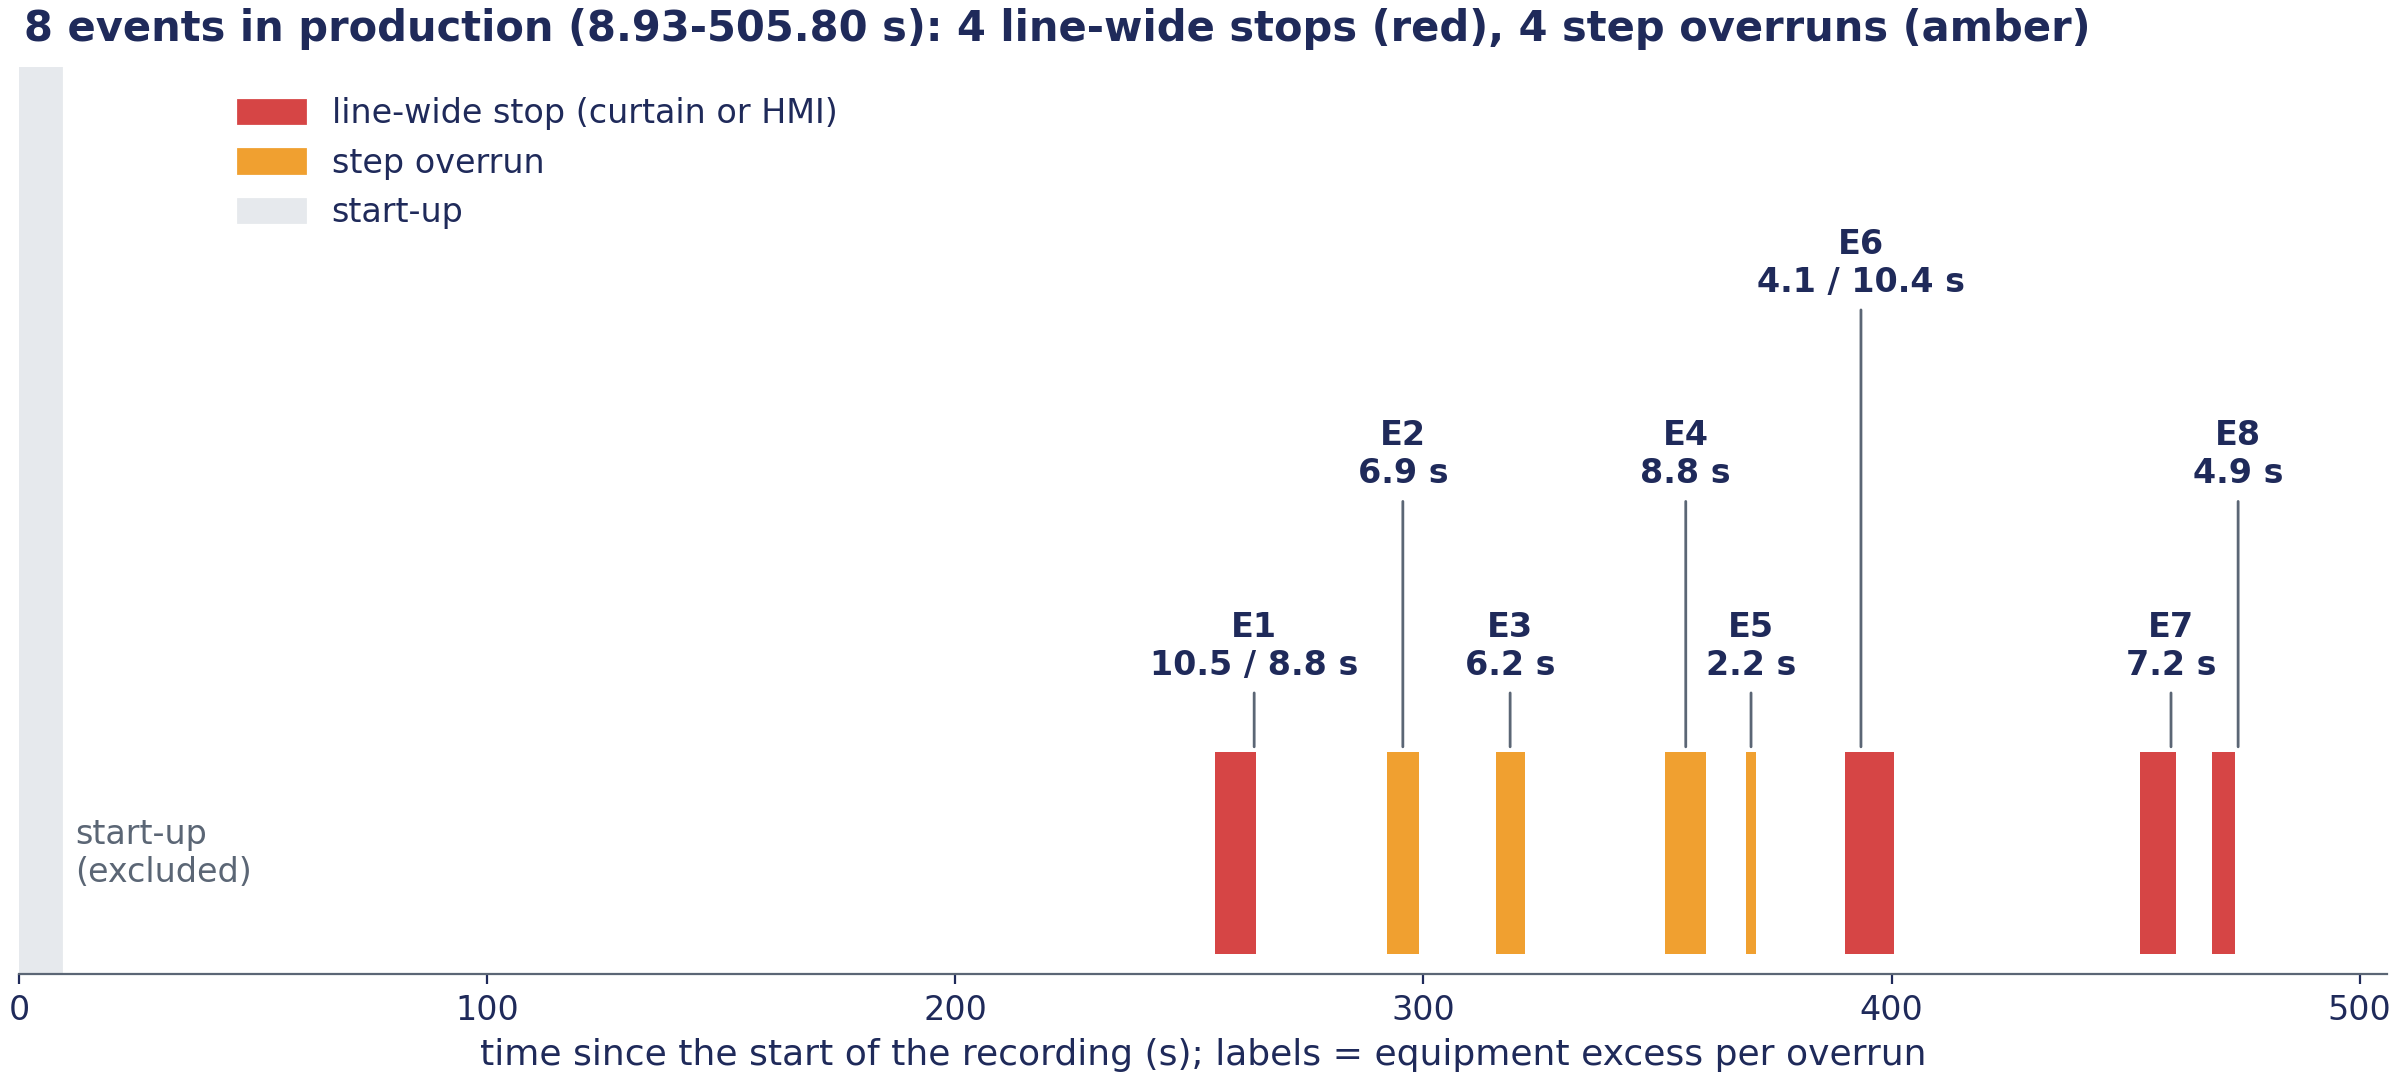

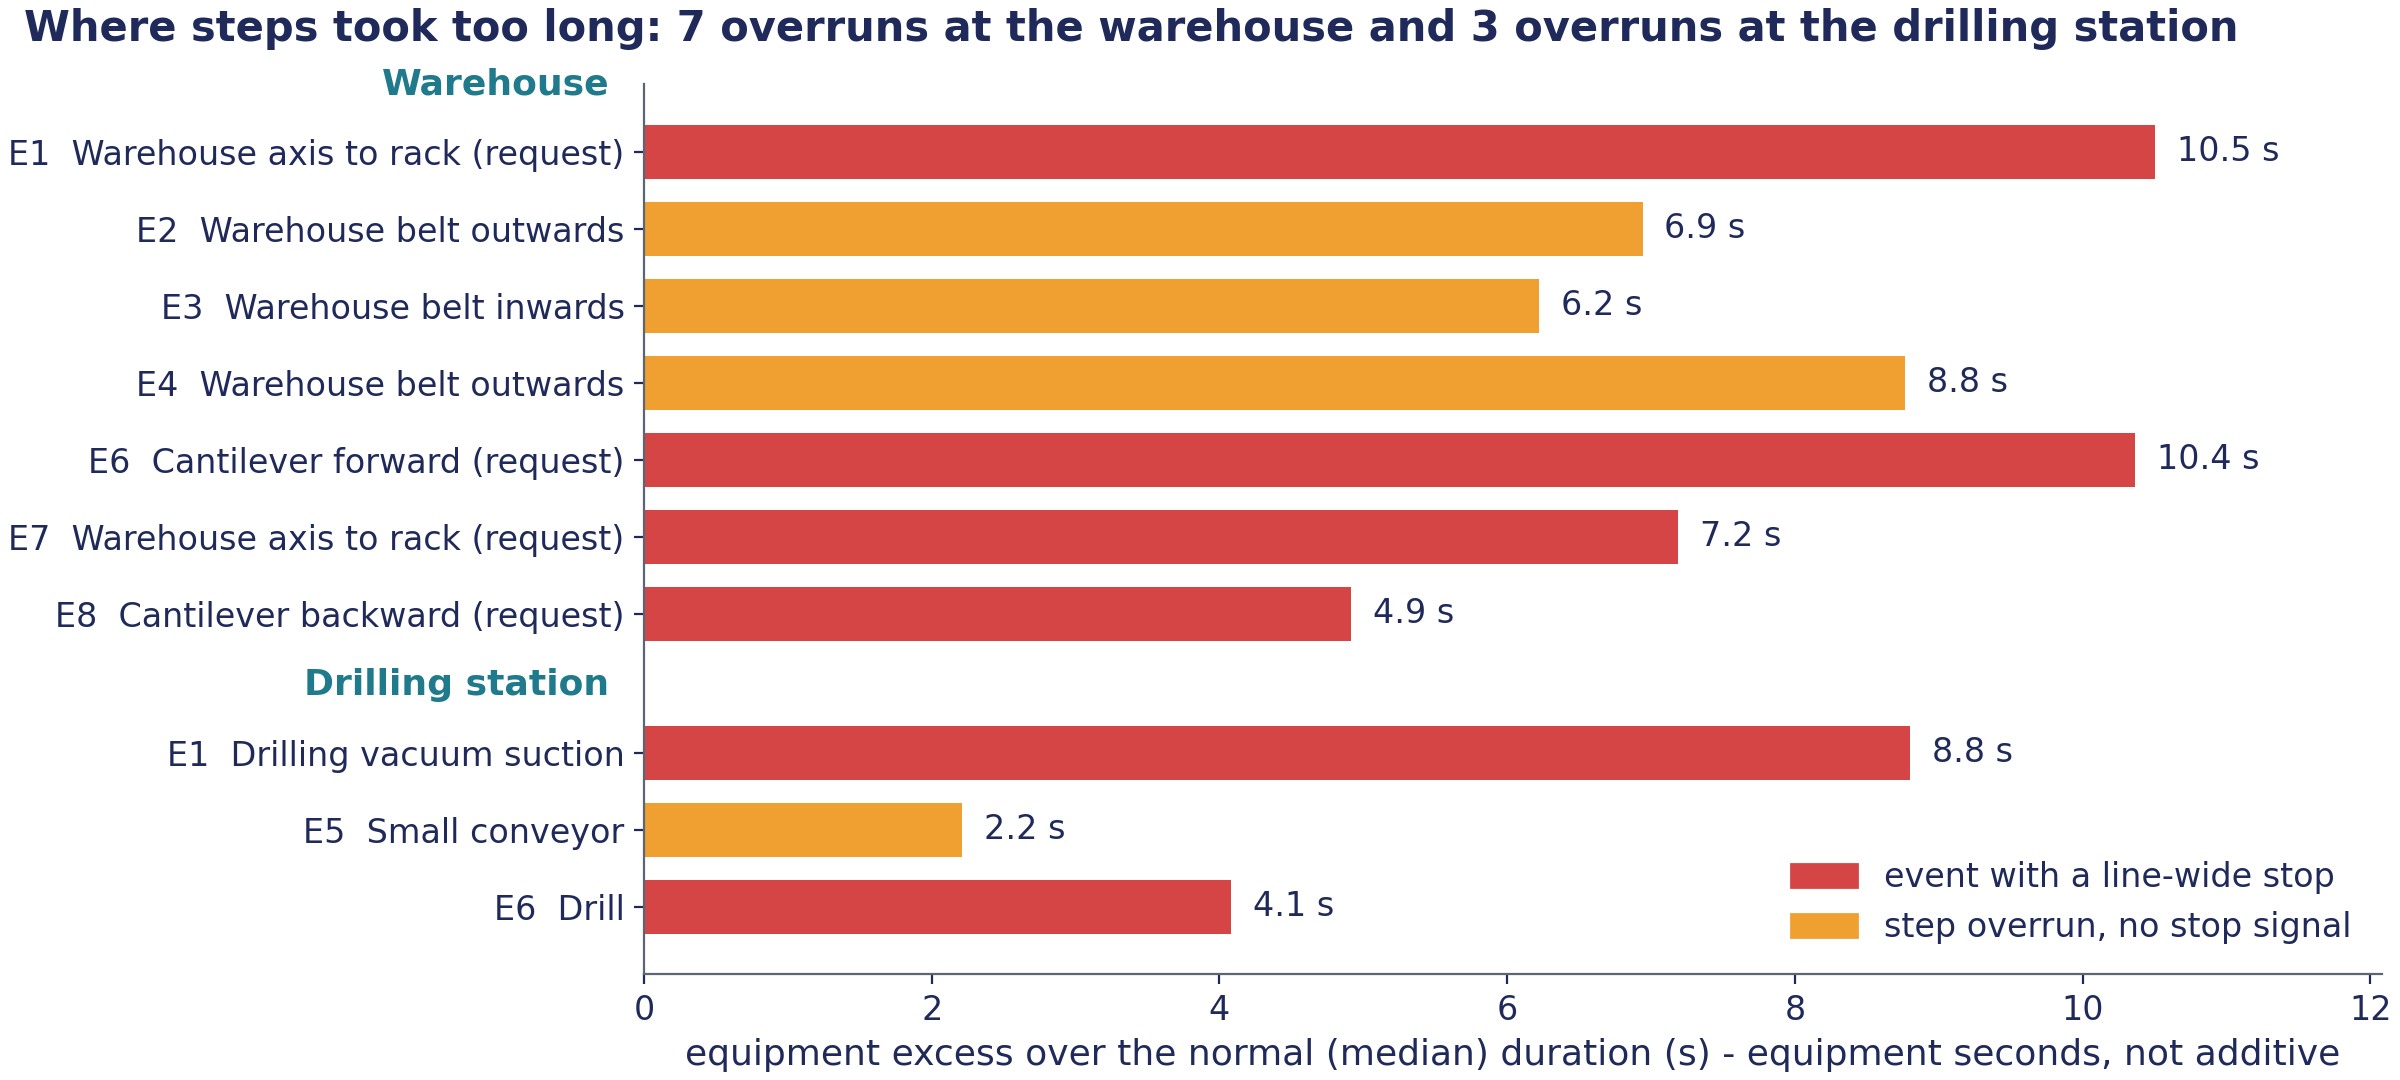

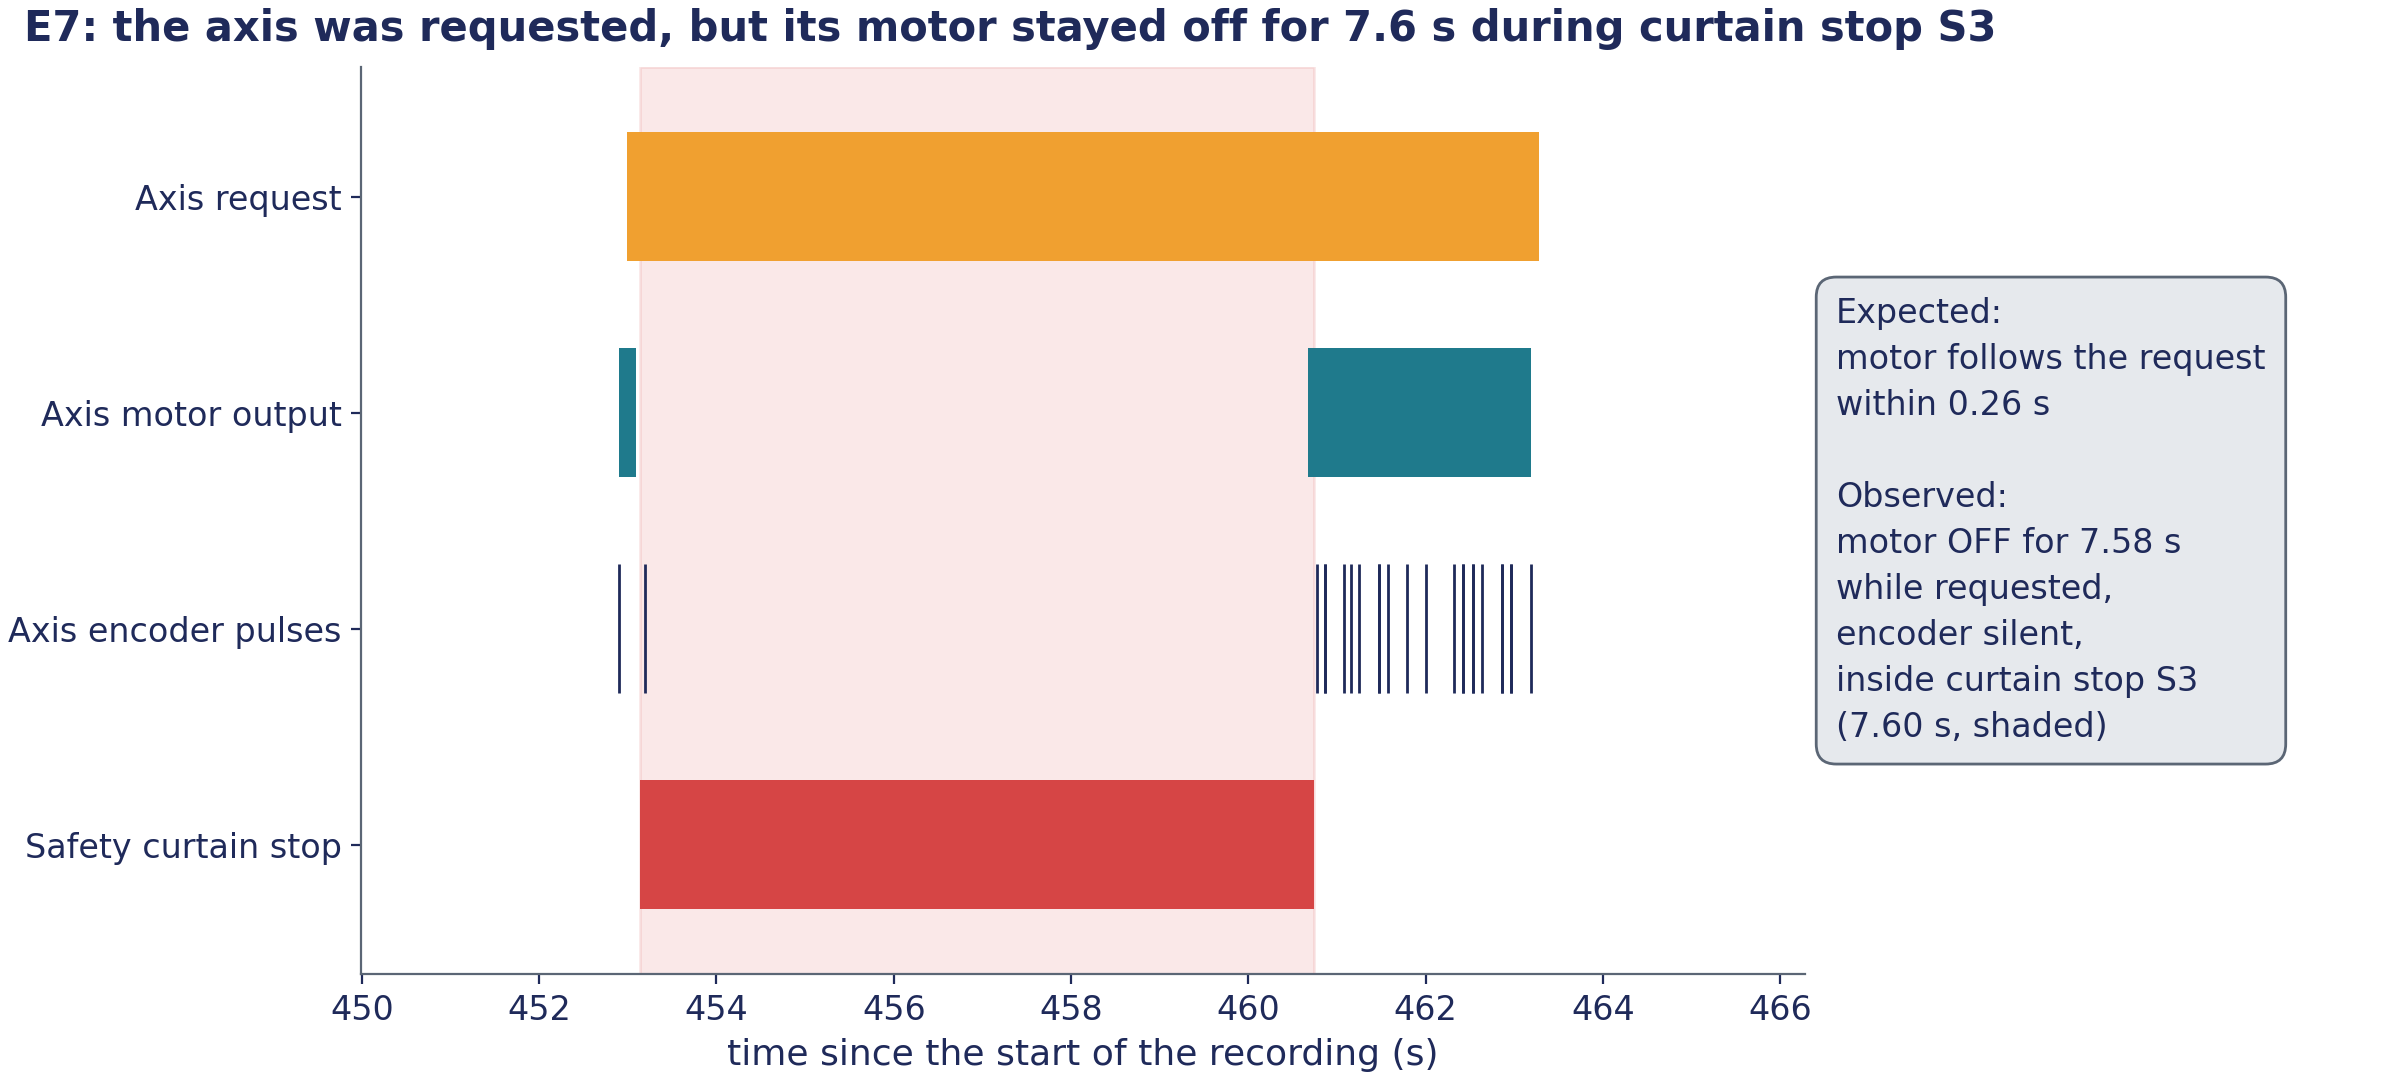

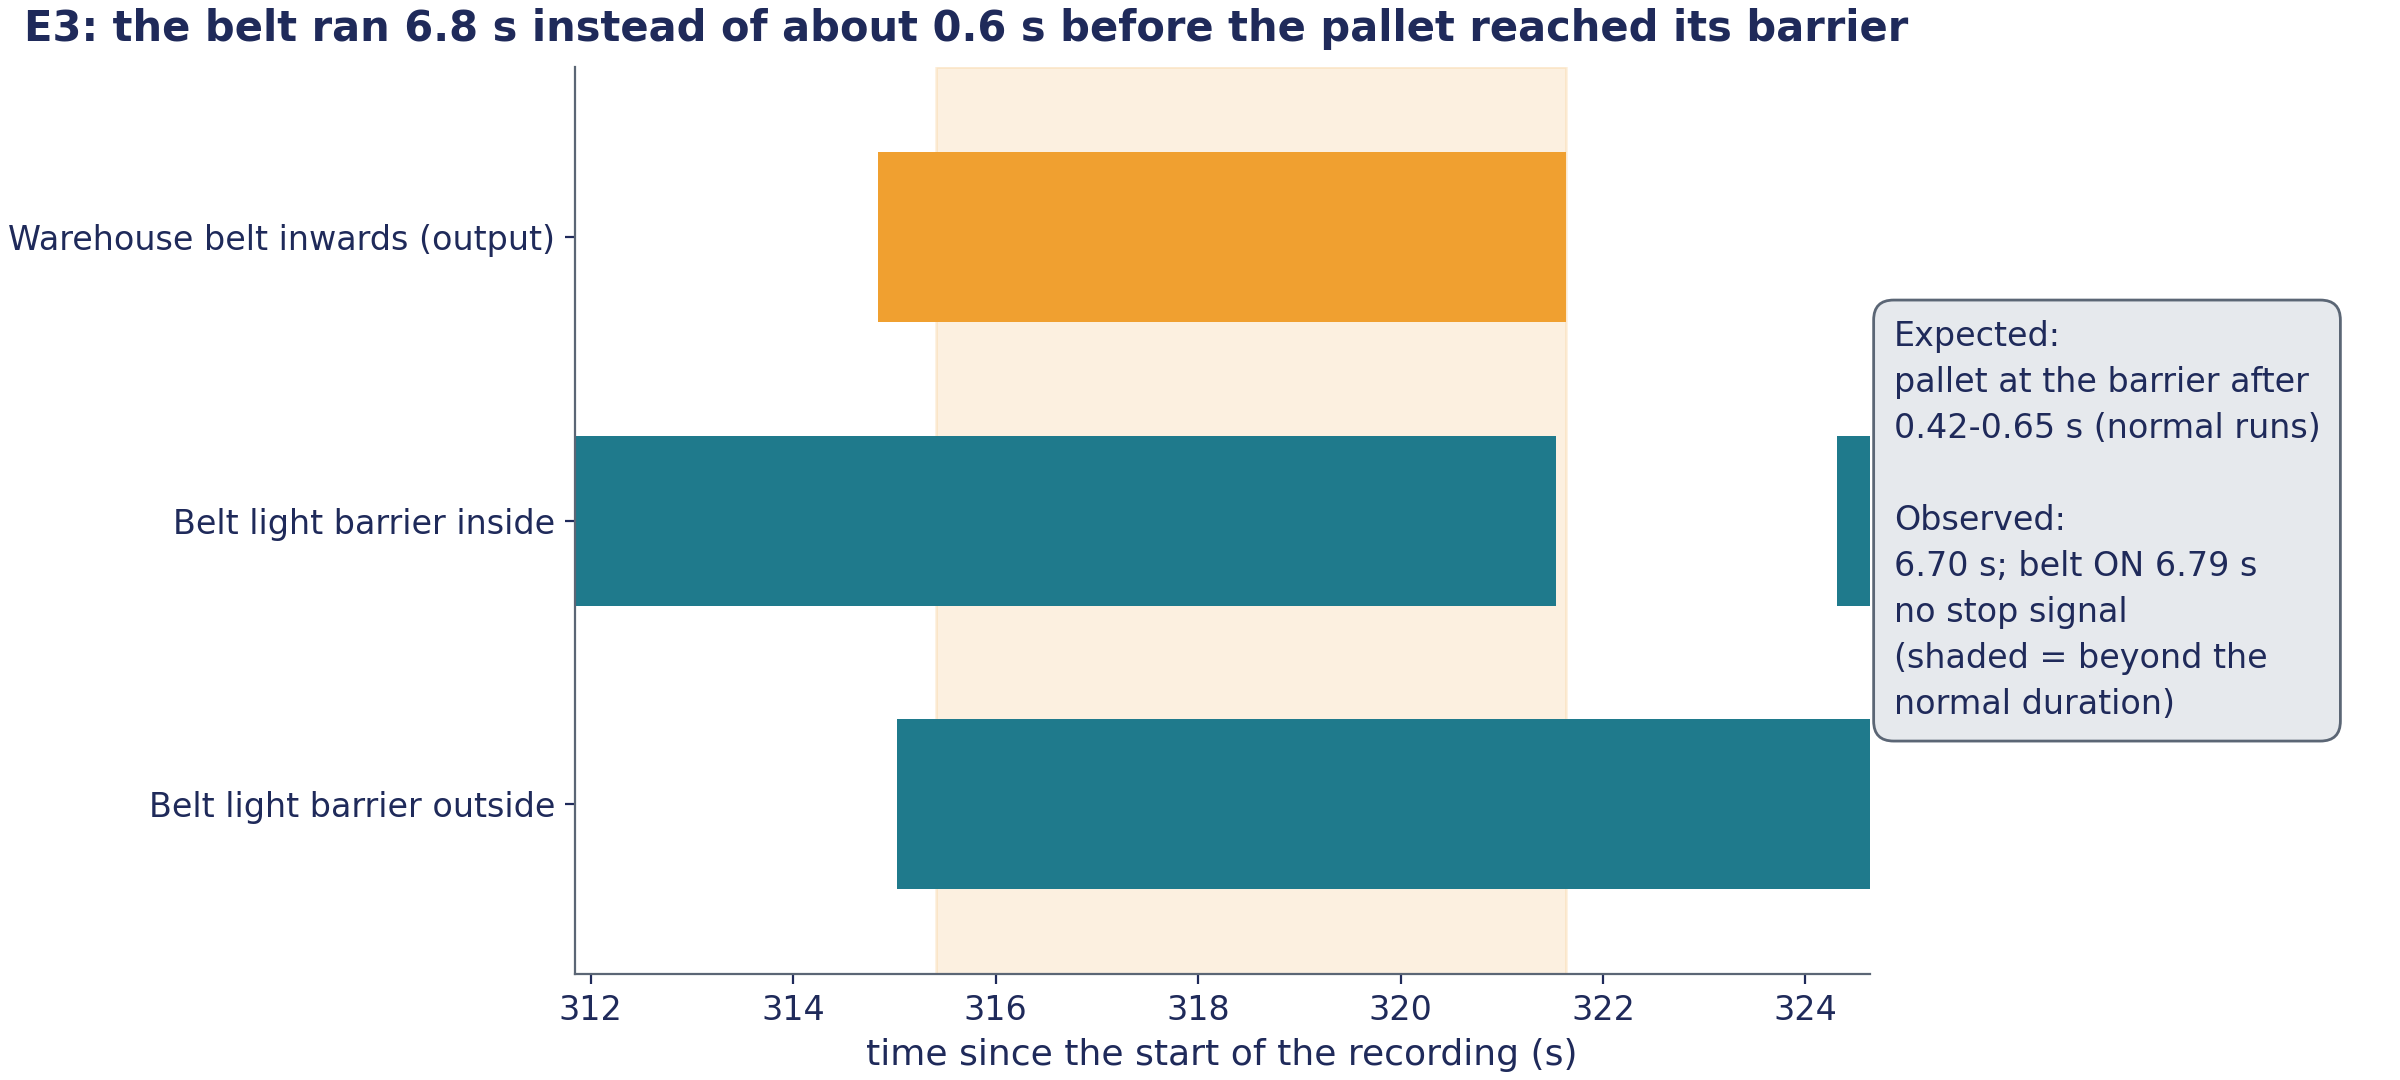

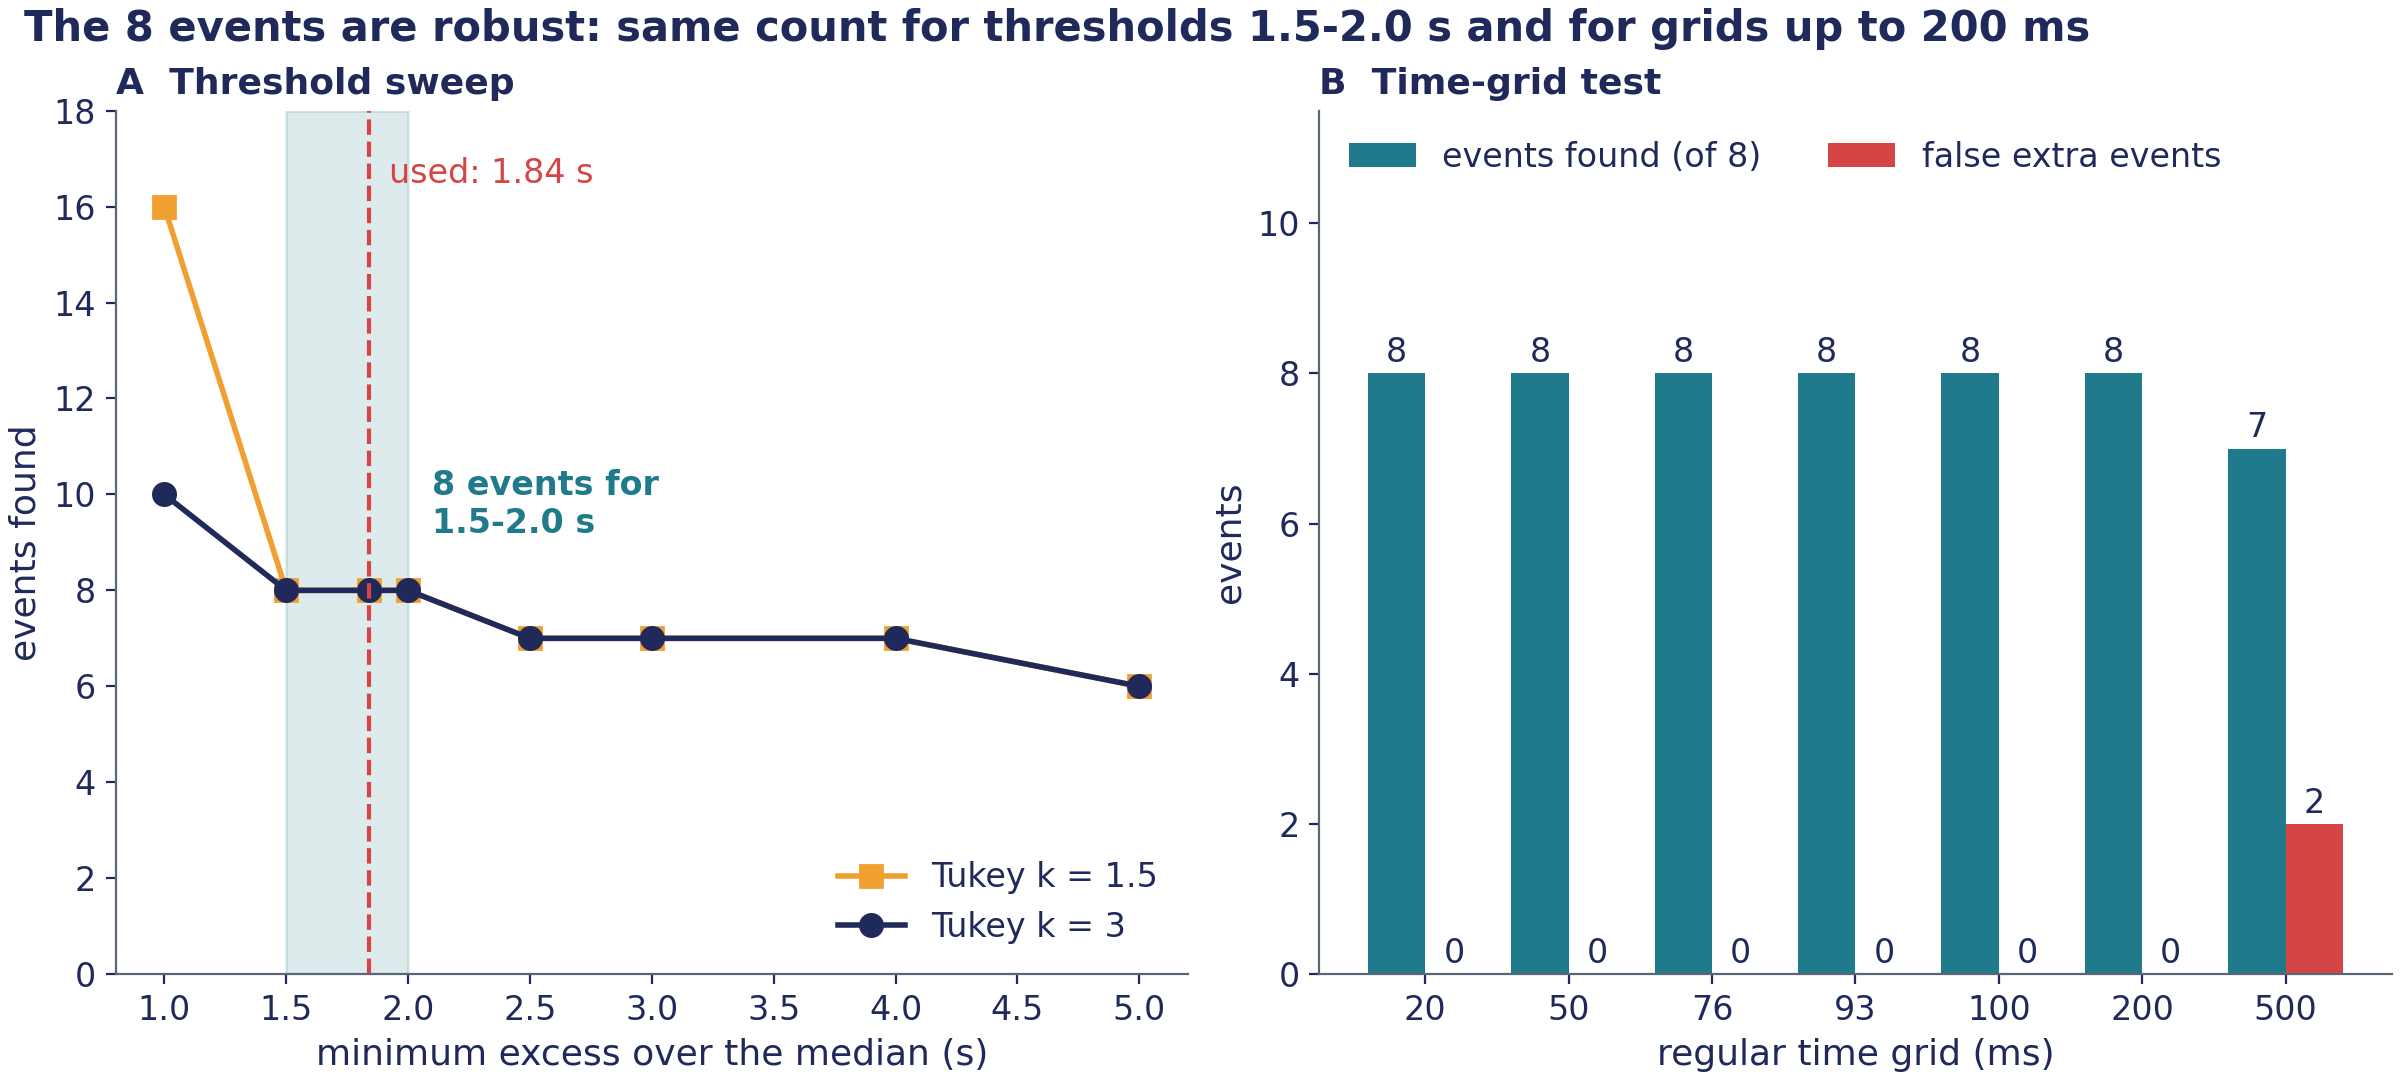

In [43]:
apply_style()            # the team's v1 helper cell above changed the matplotlib style
events, flags_s = ctx["events"], ctx["flags"]
event_timeline(events, ctx["stops"], eq, ctx["p0"], ctx["end"], FIGURES / "event_timeline.png")
attribution_bars(eq, events, FIGURES / "attribution_bars.png")
evidence_stop(data, events, ctx["stops"], ctx["drive_off_all"], FIGURES / "evidence_stop.png")
evidence_overrun(data, ctx["belt"], flags_s, FIGURES / "evidence_overrun.png")
robustness(ctx["sweep"], grid, len(events), ctx["limit"], FIGURES / "robustness.png")
med, moves = ctx["stats"]["median"], ctx["moves"]
process_flow({"belt_out": med["WH.Q1_beltForward"], "belt_in": med["WH.Q2_beltBackward"],
              "robot_1": float(moves.loc[moves["move_type"] == "pallet -> oven", "duration_s"].median()),
              "robot_2": float(moves.loc[moves["move_type"] == "lane -> pallet", "duration_s"].median()),
              "oven": float(ctx["dcyc"]["oven_phase_s"].median()), "drill": med["A1.0"], "conveyor": med["A0.7"]},
             FIGURES / "process_flow.png")
travel_figure(ctx["travel"], FIGURES / "warehouse_travel.png")
for _, ev in events.iterrows():
    event_trace(ev, flags_s, data, ctx["stops"], ctx["mw22"], eq, FIGURES / f"trace_{ev['event']}.png")
for name in ("event_timeline", "attribution_bars", "evidence_stop", "evidence_overrun", "robustness"):
    display(Image(filename=str(FIGURES / f"{name}.png"), width=900))

In [44]:
# hand over to notebooks 05-06: the Model 1 results and the time-grid test
save_stage("04_model1", {**{k: ctx[k] for k in ['flags', 'stats', 'flag_keys', 'drive_off_all', 'drive_off', 'enc', 'belt', 'belt_off_bar', 'conv', 'no_drive', 'events', 'sweep', 'alt_flags', 'mild', 'travel', 'attr', 'disp', 'robot', 'drilling']}, "grid": grid})

## Summary of Model 1

| # | Outcome |
|---|---|
| H3 | accepted - 10 activations are far too long; they form 8 events (E1-E8), the same count for k = 1.5 and 3 |
| H4 | accepted - every detection stays too long after the edge uncertainty and exceeds the longest normal run |
| H5 | standstill proven for E1, E6, E7, E8; for the belt and conveyor events E2-E5 stop or slow motion cannot be separated |
| H6 | cause visible for E1, E6, E7 (safety curtain) and E8 (HMI stop); no cause signal for E2-E5 |
| H9 | not supported - travel follows the constant-speed line, robot moves repeat, no step drifts |

**Next:** notebook 05 asks whether machine learning finds losses this rule misses.